In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pickle
from matplotlib import pyplot as plt
import os
import arviz as az
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42  # Use TrueType fonts
mpl.rcParams['ps.fonttype'] = 42

from collections import defaultdict
import numpy as np
from tqdm import tqdm
os.chdir('/nfs/home/dannis/AC-model/TIM')
from optimization import combine_posteriors


In [12]:
def chance(margin, n_scen):
    return 1 - np.exp(-n_scen * margin**2 / 2)

In [15]:
chance(0.08, 1000)

np.float64(0.9592377960216338)

## Data

In [2]:

with open('/nfs/home/dannis/AC-model/TIM/TIM_simulated_data/20251014_open_and_close/sim_data_1500_seed_100.pkl','rb') as f: 
    data = pickle.load(f)


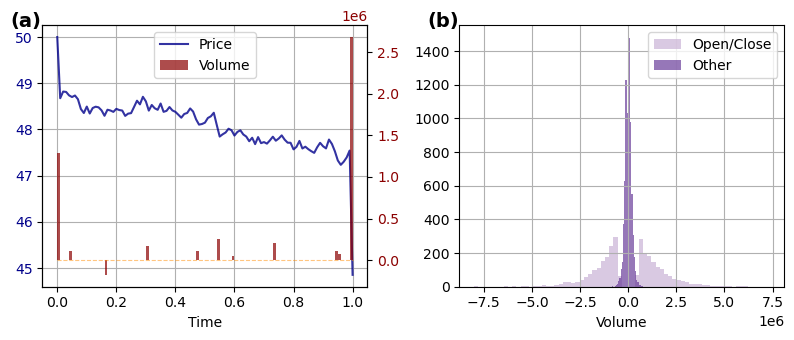

In [18]:

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

price = data[0][:, 0]
volume = data[1][:, 0]
paired_cmap = plt.cm.Paired
color_price =  'darkblue'
color_volume = 'darkred'
color_close_open = paired_cmap(8)
color_other = paired_cmap(9)
# First subplot: Price and Volume
ax2 = axes[0]

# Plot price on primary y-axis
line1 = ax2.plot(np.arange(len(price)) * 0.01, price, color=color_price, label='Price', alpha=0.8)
ax2.set_xlabel('Time')
# ax2.set_ylabel('Price', color=color_price)
ax2.tick_params(axis='y', labelcolor=color_price)
ax2.grid(True)

# Create secondary y-axis for volume
ax1 = ax2.twinx()
bars = ax1.bar(np.arange(len(volume)) * 0.01 + 0.005, volume, alpha=0.7, color=color_volume, label='Volume', width=0.01)
ax1.hlines(y=0, xmin=0, xmax=1, color='darkorange', linestyle='--', linewidth=0.8, alpha=0.5)

# ax1.set_ylabel('Volume', color=color_volume)
ax1.tick_params(axis='y', labelcolor=color_volume)
ax1.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# Add title and legend for first subplot
# axes[0].set_title('Simulated Price and Volume')

# Combine legends from both axes
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax1.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper center')

# Second subplot: Volume histogram with conditional filtering
volume_data = data[1][data[1]!=0]
n_rows = data[1].shape[0]

# Create masks for first/last rows vs middle rows
first_last_mask = np.zeros(data[1].shape, dtype=bool)
first_last_mask[0, :] = True  # First row
first_last_mask[-1, :] = True  # Last row

middle_mask = np.zeros(data[1].shape, dtype=bool)
middle_mask[1:-1, :] = True  # Middle rows

# Extract non-zero values for each category
first_last_values = data[1][first_last_mask & (data[1] != 0)]
middle_values = data[1][middle_mask & (data[1] != 0)]

# Plot histograms without edges
sns.histplot(first_last_values, bins=70, ax=axes[1], 
             alpha=0.7, label='Open/Close', color=color_close_open,
             edgecolor='none')  # Remove black edges
sns.histplot(middle_values, bins=30, ax=axes[1], 
             alpha=0.7, label='Other', color=color_other,
             edgecolor='none')  # Remove black edges

# axes[1].set_title('Volume Distribution')
axes[1].set_xlabel('Volume')
axes[1].set_ylabel('')
axes[1].legend()
axes[1].grid(True)
# Add subplot labels
axes[0].text(-0.1, 1.05, '(a)', transform=axes[0].transAxes, 
             fontsize=14, fontweight='bold', va='top', ha='left')
axes[1].text(-0.1, 1.05, '(b)', transform=axes[1].transAxes, 
             fontsize=14, fontweight='bold', va='top', ha='left')

plt.tight_layout()
plt.savefig('../plots/simulated_price_volume.pdf')
plt.show()

## Bayesian Sample Efficiency

In [4]:
from data_syn import lognormal_params

def get_true_params(kappa=5e-5, gamma=5e-5, rho=2.231):
    # Define the true parameters for the model
    true_params = {
        "kappa": kappa,   # transient impact scale
        "rho": rho,    # decay rate
        "gamma": gamma    # permanent impact scale
    }
    true_params['theta'] = true_params['kappa'] + true_params['gamma']  # theta = kappa + gamma
    true_params['alpha'] = true_params['kappa'] / true_params['theta']  # alpha = kappa / theta
    return true_params


def get_priors(prior_params):
    # Prior parameters
    t_mu, t_sigma = lognormal_params(prior_params['theta']['mean'], prior_params['theta']['std'])  # for θ
    r_mu, r_sigma = lognormal_params(prior_params['rho']['mean'], prior_params['rho']['std'])        # for rho
    # Sample from priors
    n_prior_samples = 1000
    theta_prior = np.random.lognormal(t_mu, t_sigma, n_prior_samples)
    alpha_prior = np.random.beta(prior_params['alpha']['a'], prior_params['alpha']['b'], n_prior_samples)
    rho_prior = np.random.lognormal(r_mu, r_sigma, n_prior_samples)

    # Transform to get kappa and gamma priors
    
    kappa_prior = theta_prior * alpha_prior
    gamma_prior = theta_prior * (1 - alpha_prior)


    prior_samples = {
        "kappa": kappa_prior,
        "gamma": gamma_prior,
        "rho": rho_prior,
        "theta": theta_prior,
        "alpha": alpha_prior
    }
    prior_params['kappa'] = {
        "mean": np.mean(kappa_prior),
        "std": np.std(kappa_prior)
    }
    prior_params['gamma'] = {
        "mean": np.mean(gamma_prior),
        "std": np.std(gamma_prior)
    }
        
    return prior_samples, prior_params
    



In [5]:
scaling = {"kappa": 1, "gamma": 1, "rho": 1, "theta": 1, "alpha": 1}
# Your existing code for loading posterior data
mcmc_timestamp = '20251014_open_and_close'
results_dir = os.path.join('/nfs/home/dannis/AC-model/TIM/TIM_MCMC_Results', mcmc_timestamp)

posterior_samples = {}

for nTrades in [30, 40, 50, 60, 80, 150, 250, 400, 600, 800, 1000, 1500]:
    gap = 100
    
    tim_params = ['kappa', 'gamma', 'rho', 'theta', 'alpha']
    all_vals_dict = combine_posteriors(nTrades, gap, mcmc_timestamp, tim_params)
    posterior_samples[nTrades] = all_vals_dict

df_posterior_samples = pd.DataFrame(posterior_samples)

df_posterior_samples = df_posterior_samples.reset_index().melt(
    id_vars='index',        # keep the parameter column
    var_name='ntrades',     # former column names
    value_name='value'     # list of samples
).rename(columns={'index': 'parameter',
                  'ntrades': 'nTrades'})

df_posterior_samples = df_posterior_samples.explode('value', ignore_index=True)
df_posterior_samples['value'] = df_posterior_samples['value'].astype(float)
# df_posterior_samples.groupby(['parameter', 'nTrades']).mean().unstack()



In [30]:
df_posterior_samples.groupby(['parameter', 'nTrades']).count().unstack()

value                                                          \
nTrades      30      40      50      60      80      150     250     400    
parameter                                                                   
alpha      160000  160000  160000  160000  160000  160000  160000  160000   
gamma      160000  160000  160000  160000  160000  160000  160000  160000   
kappa      160000  160000  160000  160000  160000  160000  160000  160000   
rho        160000  160000  160000  160000  160000  160000  160000  160000   
theta      160000  160000  160000  160000  160000  160000  160000  160000   

                                           
nTrades      600     800     1000    1500  
parameter                                  
alpha      160000  160000  160000  160000  
gamma      160000  160000  160000  160000  
kappa      160000  160000  160000  160000  
rho        160000  160000  160000  160000  
theta      160000  160000  160000  160000

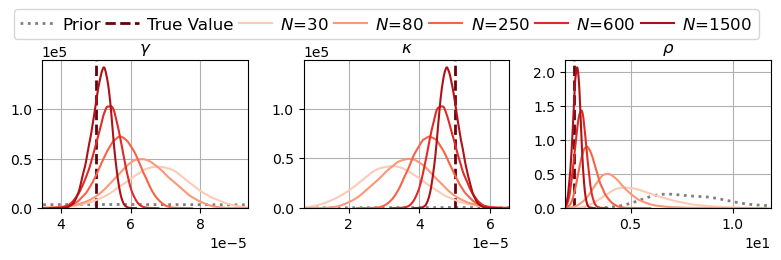

In [6]:
a_alpha, b_alpha = 2, 1
theta_mean, theta_std = 5e-4, 2e-4
rho_mean, rho_std = 8, 2
prior_params = {'theta':{'mean': theta_mean, 'std': theta_std},
                'alpha': {'a': a_alpha, 'b': b_alpha},
                'rho': {'mean': rho_mean, 'std': rho_std}
                }
true_params = get_true_params(kappa=5e-5, gamma=5e-5, rho=2.231)
prior_samples, prior_mean = get_priors(prior_params)

# Calculate correlations first
list_alpha_theta_corr = []
list_gamma_kappa_corr = []
for n in sorted(posterior_samples.keys()):
    gamma_kappa_corr = np.corrcoef(posterior_samples[n]['gamma'], posterior_samples[n]['kappa'])[0, 1]
    alpha_theta_corr = np.corrcoef(posterior_samples[n]['alpha'], posterior_samples[n]['theta'])[0, 1]
    list_alpha_theta_corr.append(alpha_theta_corr)
    list_gamma_kappa_corr.append(gamma_kappa_corr)

# Create subplots - 1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(8, 2.4))

mean_dict = defaultdict(dict)
std_dict = defaultdict(dict) 


# Store handles and labels for the shared legend
handles, labels = [], []
list_nTrades = [30, 80, 250, 600, 1500]
colors_ntrades = plt.cm.Reds(np.linspace(0.2, 1., len(list_nTrades) + 1))
# Plot the three parameters: kappa, gamma, rho
params_to_plot = ['gamma', 'kappa', 'rho']
for i, param in enumerate(params_to_plot):
    # Plot prior
    line_prior = sns.kdeplot(prior_samples[param]*scaling[param], fill=False, ax=axes[i], 
                color='grey', linestyle=':', linewidth=2, label='Prior')
    
    # Plot true value
    line_true = axes[i].axvline(true_params[param]*scaling[param], color=colors_ntrades[-1], linestyle='--', 
                    linewidth=2, label='True Value')
    
    # Only collect handles from the first subplot to avoid duplicates
    if i == 0:
        handles.append(line_prior.get_lines()[0])
        handles.append(line_true)
        labels.extend(['Prior', 'True Value'])
    
    xmin = np.inf
    xmax = -np.inf

    # Plot posteriors for each n
    for j, n in enumerate(list_nTrades):
        vals = df_posterior_samples[(df_posterior_samples['parameter'] == param) & 
                                    (df_posterior_samples['nTrades'] == n)]['value'].values

        mean = np.mean(vals)
        std = np.std(vals)
        
        line_post = sns.kdeplot(vals*scaling[param], fill=False, ax=axes[i], 
                   label=f'$N$={n}', color=colors_ntrades[j])
        
        # Only collect posterior handles from the first subplot
        if i == 0:
            handles.append(line_post.get_lines()[-1])
            labels.append(f'$N$={n}')
            
        mean_dict[param][n] = mean
        std_dict[param][n] = std
        xmin = min(xmin, np.quantile(vals*scaling[param], 0.001))
        xmax = max(xmax, np.quantile(vals*scaling[param], 0.999))
    
    axes[i].set_xlim(xmin, xmax)
    axes[i].set_title(f'$\{param}$', fontsize=12)

    axes[i].grid(True)
    
    # Format axes in scientific notation
    axes[i].ticklabel_format(style='scientific', axis='x', scilimits=(0,0))
    axes[i].ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
axes[0].set_ylabel('')
axes[1].set_ylabel('')
axes[2].set_ylabel('')
# Create a shared legend at the top
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.1), 
           ncol=len(labels), fontsize=12, frameon=True, 
           columnspacing=0.3, handletextpad=0.5)

plt.tight_layout()
plt.savefig('../plots/posteriors.pdf', bbox_inches='tight')
plt.show()

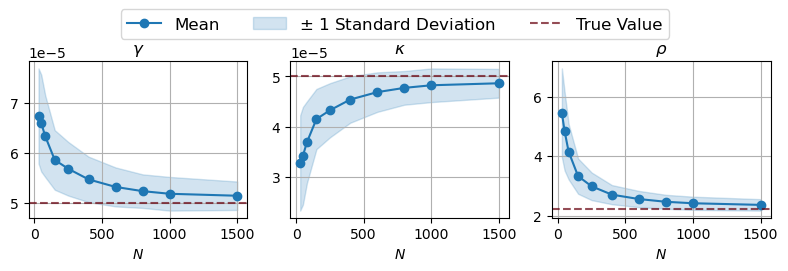

In [7]:
df_mean = df_posterior_samples.groupby(['nTrades', 'parameter']).mean().unstack().drop(index=[40, 60])
df_std = df_posterior_samples.groupby(['nTrades', 'parameter']).std().unstack().drop(index=[40, 60])
df_mean.columns = df_mean.columns.droplevel(0)
df_std.columns = df_std.columns.droplevel(0)

# Create the lineplot first
params_to_plot = ['gamma', 'kappa', 'rho']
fig, axes = plt.subplots(1, len(params_to_plot), figsize=(8, 2.5), sharex=True)

# Store handles and labels for shared legend
handles, labels = [], []

for i, param in enumerate(params_to_plot):
    ax = axes[i] if len(params_to_plot) > 1 else axes
    
    line1 = ax.plot(df_mean.index, df_mean[param], marker='o', label=f'Mean of {param}')
    fill = ax.fill_between(df_mean.index, 
                    df_mean[param] - df_std[param], 
                    df_mean[param] + df_std[param], 
                    color='C0', alpha=0.2, label=f'STD of {param}')
    line2 = ax.axhline(true_params[param] * scaling[param], color=colors_ntrades[-1], linestyle='--', alpha=0.7, label=f'True {param}')
    
    # Collect handles from first subplot only
    if i == 0:
        handles.extend([line1[0], fill, line2])
        labels.extend([f'Mean', r'$\pm$ 1 Standard Deviation', f'True Value'])
    
    ax.set_title(f'$\\{param}$', fontsize=12)
    ax.set_xlabel(r'$N$')
    # ax.set_ylabel('Mean Value')
    ax.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    ax.grid(True)

# Create shared legend outside the plot area
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.1), 
           ncol=len(labels), fontsize=12, frameon=True)

plt.tight_layout()
plt.savefig('../plots/posterior_convergence.pdf', bbox_inches='tight')
plt.show()

In [27]:
dir = '/nfs/home/dannis/AC-model/TIM/TIM_MCMC_Results/20251008_poisson'
r = []
for file in os.listdir(dir):
    if file.endswith('.nc'):
        ntrades = int(file.split('_')[1])
        seed = int(file.split('_')[-1].split('.')[0])
        r.append({'ntrades': ntrades, 'seed': seed})

In [21]:
np.abs(1 - df_mean.divide(pd.Series(true_params), axis=1))[['kappa', 'gamma', 'rho']]

,kappa,gamma,rho
nTrades,,,
30,0.403814,0.406970,1.491205
50,0.317690,0.317219,1.143077
80,0.262887,0.261927,0.823900
150,0.145633,0.145329,0.444336
250,0.095027,0.096633,0.292203
400,0.056256,0.057633,0.193795
600,0.066487,0.066870,0.178560
800,0.051986,0.051684,0.133896
1000,0.042884,0.042621,0.105557


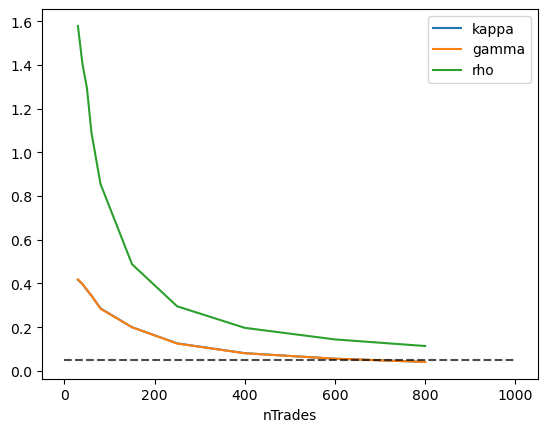

In [16]:
np.abs(1 - df_mean.divide(pd.Series(true_params), axis=1))[['kappa', 'gamma', 'rho']].plot()
plt.hlines(y=0.05, xmax=1000, xmin=0, color='black', linestyle='--', alpha=0.7)

## Optimization with Various Constraint tightness

In [4]:
def get_str_inbetween(s, start, end):
    return (s.split(start))[1].split(end)[0]

def get_mip_info(base_dir):
    # Storage for all trade data
    # Initialize list to store data
    data_rows = []

    # Iterate through subfolders
    for subfolder in tqdm(os.listdir(base_dir)):
        subfolder_path = os.path.join(base_dir, subfolder)
        if os.path.isdir(subfolder_path):            
            # Iterate through files in subfolder
            nTrades = int(get_str_inbetween(subfolder, 'nTrades', '_'))
            nScenarios = int(get_str_inbetween(subfolder, 'nScenarios', '_'))
            lossThresh = float(get_str_inbetween(subfolder, 'lossThresh', '_'))
            chanceThresh = float(get_str_inbetween(subfolder, 'chanceThresh', '_')) / 100
            M = int(get_str_inbetween(subfolder, 'M', '_'))
            scale = int(get_str_inbetween(subfolder, 'scale', '_'))
            sigma = float(get_str_inbetween(subfolder, 'sigma', '_')) if 'sigma' in subfolder else np.nan

            row = {
                'nTrades': nTrades,
                'nScenarios': nScenarios,
                'lossThresh': lossThresh,
                'chanceThresh': chanceThresh,
                'M': M,
                'scale': scale,
                'sigma': sigma
            }
            for filename in os.listdir(subfolder_path):
                if filename.endswith('.pkl'):
                    file_path = os.path.join(subfolder_path, filename)
                    # print(f"  Reading file: {filename}")
                    
                    with open(file_path, 'rb') as f:
                        data = pickle.load(f)
                    
                    trades = np.array(data['trades'])
                    seed = int(filename.split('_')[-1].split('.')[0])
                    
                    # Extract key info from filename and subfolder
                    row.update({
                        'subfolder': subfolder,
                        'filename': filename,
                        'status': data.get('status', 'unknown'),
                        'chance_slack': data.get('chance_slack', np.nan),
                        'obj_val': data.get('obj_val', np.nan),
                        'runtime': data.get('runtime', np.nan),
                        'seed': seed,
                    })
                    
                    for j, trade in enumerate(trades):
                        row[f'trade_{j}'] = trade

                    data_rows.append(row.copy())

    # Create DataFrame
    df = pd.DataFrame(data_rows)
    
    return df

In [3]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results/20251017_open_and_close']

# Combine data from multiple directories
all_data = []
for base_dir in base_dirs:
    df = get_mip_info(base_dir)
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

  0%|          | 0/65 [00:00<?, ?it/s]

100%|██████████| 65/65 [00:00<00:00, 127.30it/s]


In [4]:
with open('/nfs/home/dannis/AC-model/TIM_opt_results/20251017_open_and_close/nTrades800_nScenarios1000_lossThresh451000_chanceThresh2_M1000000_mcmcLabelcombined_scale100_sigma0.95_/nScenarios1000_100.pkl', 'rb') as f:
    data = pickle.load(f)

In [5]:
combined_df['failure_rate'] = (1-combined_df['chance_slack']) * combined_df['chanceThresh'] 
combined_df.groupby(['nTrades', 'chanceThresh']).agg({
    'obj_val': ['mean', 'std'], 
    'failure_rate': ['mean', 'std'],
    'status': [('optimal rate', lambda x: (x == 2).mean()),
        ('count', 'count')],
    'runtime': ['mean', 'std']})

obj_val              failure_rate            \
                               mean          std         mean       std   
nTrades chanceThresh                                                      
80      0.02                    NaN          NaN          NaN       NaN   
        0.03                    NaN          NaN          NaN       NaN   
        0.04                    NaN          NaN          NaN       NaN   
        0.05          386258.033189   464.366329     0.050000  0.000000   
        0.07          386102.078339  4165.253019     0.069808  0.000491   
        0.10          381004.296666  1903.365519     0.096800  0.003818   
150     0.02          384596.542230          NaN     0.020000       NaN   
        0.03          383526.804352  4116.918033     0.029929  0.000267   
        0.04          380646.559582  4444.095960     0.039600  0.000770   
        0.05          376461.080965  2690.698814     0.049433  0.001040   
        0.07          374137.482423  1569.588220     0.066167  0.003505   
        0.10          373926.375386  1440.315744     0.072100  0.006784   
250     0.02          384571.451241  3020.588333     0.020000  0.000000   
        0.03          382799.467883  5511.381948     0.029696  0.000765   
        0.04          378866.208457  4643.951150     0.039833  0.000461   
        0.05          375310.406716  2538.771636     0.049133  0.001106   
        0.07          373465.670310  1527.825966     0.064100  0.005208   
        0.10          373361.717131  1418.808832     0.066967  0.007495   
400     0.02          380252.959870  3043.552872     0.020000  0.000000   
        0.03          378010.679871  4310.925563     0.029966  0.000186   
        0.04          374071.850311  2661.585677     0.039800  0.000484   
        0.05          372525.435247  1840.086562     0.048667  0.002294   
        0.07          371688.058592  1419.524428     0.061133  0.007343   
        0.10          371676.454714  1424.366567     0.062567  0.008748   
600     0.02          378805.040246  4805.837422     0.020000  0.000000   
        0.03          373658.030778  2627.945684     0.029933  0.000254   
        0.04          371215.424961  1912.535483     0.039733  0.000691   
        0.05          370499.838515  1584.132175     0.048200  0.002156   
        0.07          370047.191372  1409.413449     0.056567  0.007181   
        0.10          370047.191372  1409.413449     0.056633  0.007318   
800     0.02          378214.246503  5402.108181     0.020000  0.000000   
        0.03          372923.955038  2897.940012     0.030000  0.000000   
        0.04          370969.203629  1935.158150     0.038967  0.001608   
        0.05          370103.400092  1627.314883     0.048333  0.002695   
        0.07          369749.866294  1435.981303     0.055000  0.007865   
        0.10          369749.866294  1435.981303     0.055000  0.007865   
1000    0.02          376465.040463  4737.629521     0.020000  0.000000   
        0.03          372051.721180  2473.628205     0.030000  0.000000   
        0.04          370299.414685  1781.389731     0.039400  0.001248   
        0.05          369677.034544  1535.497454     0.046733  0.003463   
        0.07          369386.625754  1371.939766     0.052667  0.007716   
        0.10          369386.625754  1371.939766     0.052667  0.007716   
1500    0.02          377892.816209  5165.663584     0.020000  0.000000   
        0.03          372094.684217  2528.814672     0.029967  0.000183   
        0.04          370462.348739  1744.586253     0.039267  0.001574   
        0.05          369816.638595  1463.524070     0.047267  0.003403   
        0.07          369586.089019  1353.887313     0.052567  0.006882   
        0.10          369586.089019  1353.887313     0.052567  0.006882   
99999   0.02          376704.640154  4326.752097     0.020000  0.000000   
        0.03          371345.464524  1991.769135     0.029800  0.000925   
        0.04          369748.340286  1739.954801     

In [10]:
combined_df.runtime.mean()

np.float64(1078.4326294413809)

In [9]:
combined_df.runtime.quantile([0.1,0.5,0.95])

0.10        1.117153
0.50       12.499898
0.95    10800.565067
Name: runtime, dtype: float64

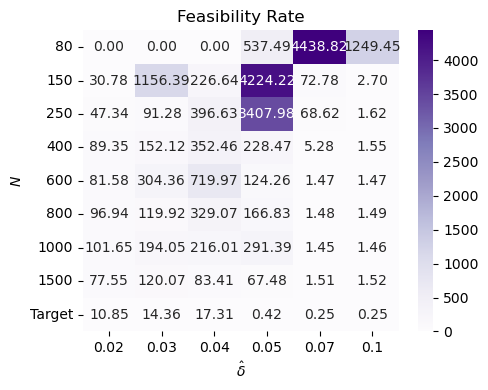

In [25]:
# First plot: Heatmap
fig, ax = plt.subplots(figsize=(5, 4))

runtime = combined_df[combined_df['status'] == 2].groupby(['nTrades', 'chanceThresh']).agg({
    'runtime': lambda x: x.quantile(0.9)}).unstack().fillna(0)
runtime.columns = runtime.columns.droplevel(0)
sns.heatmap(runtime, annot=True, fmt=".2f", cmap='Purples', ax=ax)

yticklabels = ax.get_yticklabels()
yticklabels[-1].set_text('Target')
ax.set_yticklabels(yticklabels);
ax.set_title('Feasibility Rate')
ax.set_xlabel(r'$\hat{{\delta}}$')
ax.set_ylabel(r'$N$')

plt.tight_layout()
# plt.savefig('../plots/feasibility_heatmap.pdf', bbox_inches='tight')
plt.show()


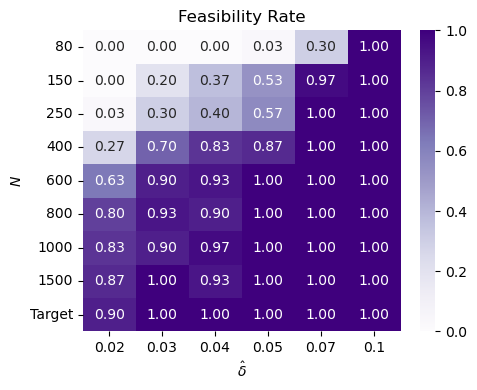

In [ ]:
# First plot: Heatmap
fig, ax = plt.subplots(figsize=(5, 4))

optimal_rate = combined_df.groupby(['nTrades', 'chanceThresh']).agg({
    'status': [('optimal rate', lambda x: (x == 2).mean())]}).unstack().fillna(0)
optimal_rate.columns = optimal_rate.columns.droplevel(0).droplevel(0)
sns.heatmap(optimal_rate, annot=True, fmt=".2f", cmap='Purples', ax=ax)

yticklabels = ax.get_yticklabels()
yticklabels[-1].set_text('Target')
ax.set_yticklabels(yticklabels);
ax.set_title('Feasibility Rate')
ax.set_xlabel(r'$\hat{{\delta}}$')
ax.set_ylabel(r'$N$')

plt.tight_layout()
# plt.savefig('../plots/feasibility_heatmap.pdf', bbox_inches='tight')
plt.show()


In [10]:
def IS_tim(action, posterior_samples, n_steps, total_qty, tau, sigma, spread):
    """
    Pure NumPy implementation of IS_tim_particles.
    Returns realized IS values across posterior scenarios.
    """
    
    n_scenarios = len(posterior_samples['gamma'])
    np.random.seed(42)
    # Gaussian noise: shape (n_scenarios, n_steps+1)
    noise = np.random.normal(0, 1, (n_scenarios, n_steps + 1))
    
    # Extract posterior params
    kappa = np.array(posterior_samples["kappa"])  # (n_scenarios,)
    gamma = np.array(posterior_samples["gamma"])  # (n_scenarios,)
    rho = 2.231  # could also be np.array if sampled
    
    # Precompute action terms
    action = np.asarray(action)
    action_sq_sum = np.sum(action**2)
    action_cumsum = np.cumsum(action)
    inventory = total_qty - action_cumsum  # shape (n_steps+1,)
    
    # Permanent impact
    permanent_impact = 0.5 * gamma * total_qty**2 - 0.5 * gamma * action_sq_sum
    
    # Spread cost (same for all scenarios)
    spread_cost = spread * total_qty
    
    # Temporary impact
    temporary_impact = 0.5 * (gamma + kappa) * action_sq_sum
    
    # Stochastic term: sum_k inventory[k] * noise[p, k]
    stochastic_term = sigma * np.sqrt(tau) * (noise @ inventory)
    
    # Transient impact
    time_idx = np.arange(n_steps + 1)
    # exp(-rho * tau * (k - i)) for k>i
    kernel = np.exp(-rho * tau * (time_idx[None, :] - time_idx[:, None]))
    kernel = np.triu(kernel, k=1)  # zero out k <= i
    
    transient_impact_per_action = action @ (kernel @ action)  # scalar
    transient_impact = kappa * transient_impact_per_action
    
    # IS values per scenario
    IS_exprs = permanent_impact + spread_cost + temporary_impact - stochastic_term + transient_impact
    # print(f'permanent_impact: {permanent_impact}, temporary_impact: {temporary_impact}, stochastic_term: {stochastic_term}, transient_impact: {transient_impact}')
    return IS_exprs

In [11]:
kappa = 5e-5
gamma = 5e-5
sigma = 0.
rho = 2.231
scale= 100
n_scenarios = 1
total_qty = 1e5
n_steps = 10
tau = 0.1
spread = 0
loss_thresh = 4.5e5
posterior_samples = {"gamma": [gamma]*n_scenarios, "kappa": [kappa]*n_scenarios, "rho": [rho]*n_scenarios}

dict_expected_IS = []
dict_p_violation = []
trade_cols = [f'trade_{j}' for j in range(11)]
for (nTrades, chanceThresh), group in tqdm(combined_df.groupby(['nTrades', 'chanceThresh'])):
    trades = group[group['status']==2][trade_cols] * scale
    for idx, row in trades.iterrows():
        IS = IS_tim(np.array(row), posterior_samples, n_steps, total_qty, tau, sigma, spread)
        dict_expected_IS.append({'nTrades': nTrades, 'chanceThresh': chanceThresh, 'expected_IS': IS.mean()})
        dict_p_violation.append({'nTrades': nTrades, 'chanceThresh': chanceThresh, 'p_vio': np.mean(IS > loss_thresh)})
df_expected_IS = pd.DataFrame(dict_expected_IS)

100%|██████████| 50/50 [00:00<00:00, 242.88it/s]


<Axes: xlabel='nTrades', ylabel='expected_IS'>

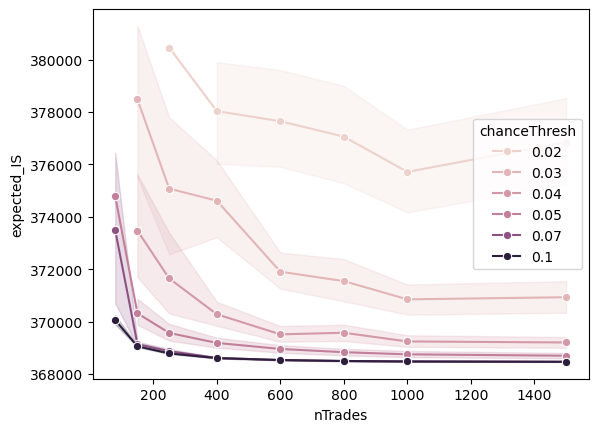

In [12]:
df_expected_IS = pd.DataFrame(dict_expected_IS)

sns.lineplot(data=df_expected_IS[df_expected_IS['nTrades']<99999], x='nTrades', y='expected_IS', hue='chanceThresh', marker='o')

[Text(0, 0.5, '80'),
 Text(0, 1.5, '150'),
 Text(0, 2.5, '250'),
 Text(0, 3.5, '400'),
 Text(0, 4.5, '600'),
 Text(0, 5.5, '800'),
 Text(0, 6.5, '1000'),
 Text(0, 7.5, '1500'),
 Text(0, 8.5, 'Target')]

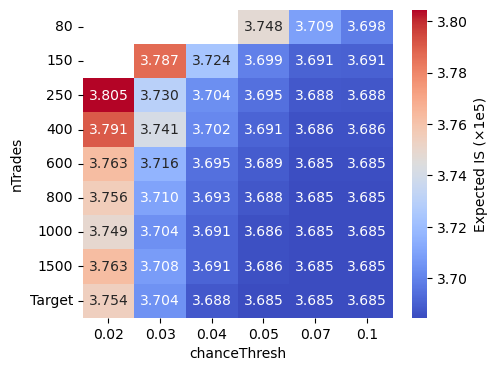

In [13]:
plt.figure(figsize=(5,4))

# Scale the data by 1e-5 for display
df_heatmap_data = df_expected_IS.groupby(['nTrades', 'chanceThresh'])['expected_IS'].median().unstack()
df_scaled = df_heatmap_data * 1e-5

ax = sns.heatmap(df_scaled, annot=True, fmt=".3f", cmap="coolwarm", 
                 cbar_kws={'label': 'Expected IS (×1e5)'})

# Get current y-tick labels and modify the last one
yticklabels = ax.get_yticklabels()
yticklabels[-1].set_text('Target')
ax.set_yticklabels(yticklabels)

/tmp/ipykernel_795631/2547376039.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=axes[i], palette='Blues')
/tmp/ipykernel_795631/2547376039.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(xticklabels)
/tmp/ipykernel_795631/2547376039.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=axes[i], palette='Blues')
/tmp/ipykernel_795631/2547376039.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocato

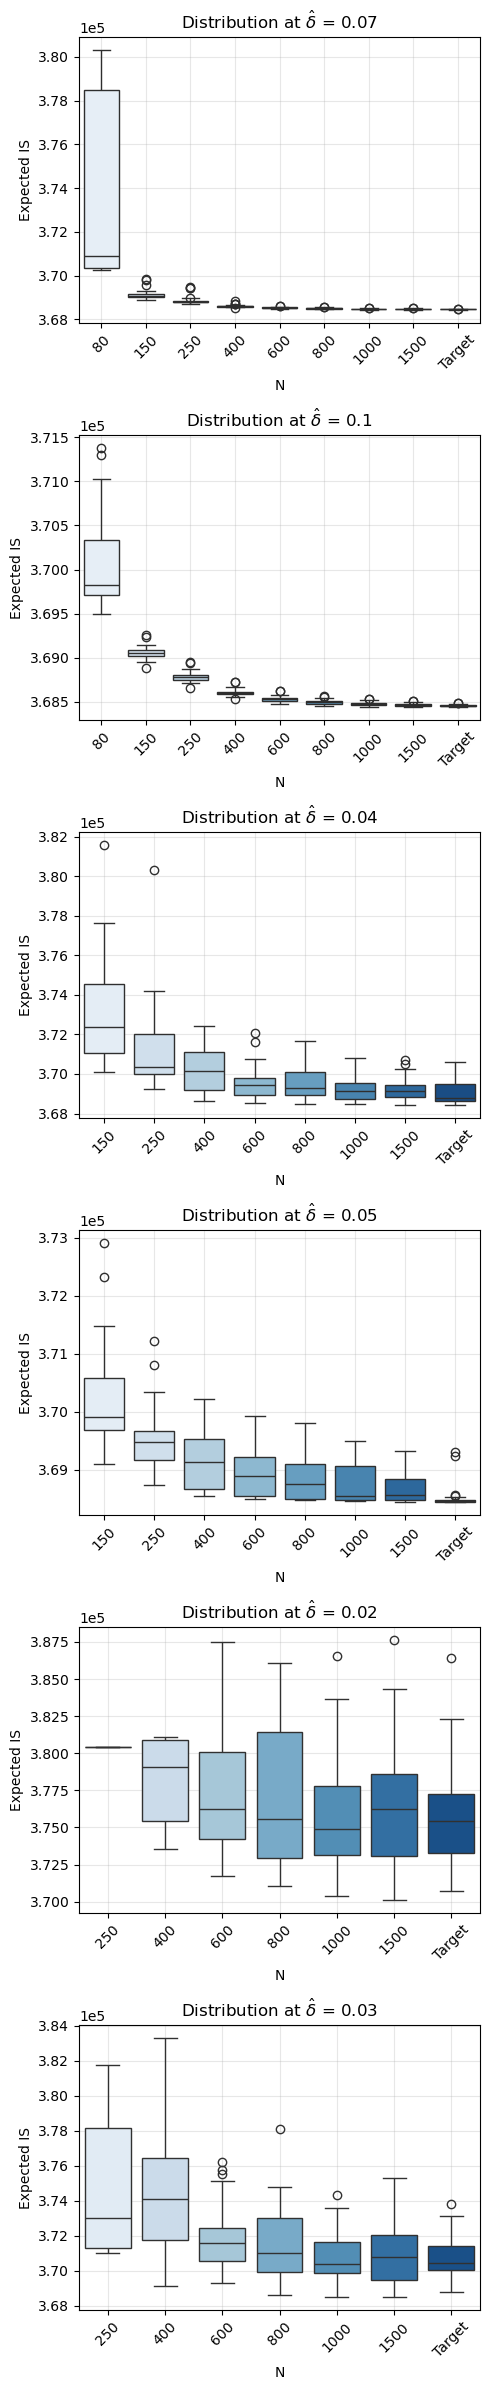

In [10]:

# Create subplots for different chanceThresh values
nTrades_values = df_expected_IS['chanceThresh'].unique()
fig, axes = plt.subplots(len(nTrades_values), 1, figsize=(5, 4 * len(nTrades_values)))

for i, nTrades in enumerate(nTrades_values):
    # Filter data for specific chanceThresh
    df_filtered = df_expected_IS[df_expected_IS['chanceThresh'] == nTrades]
    
    # Create boxplot with Blues color palette
    sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=axes[i], palette='Blues')
    
    # Set titles and labels
    axes[i].set_title(f'Distribution at $\\hat{{\\delta}}$ = {nTrades}')
    axes[i].set_xlabel('N')
    axes[i].set_ylabel('Expected IS')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    axes[i].grid(True, alpha=0.3)
    
    # Get current x-tick labels and modify the last one to 'Target'
    xticklabels = axes[i].get_xticklabels()
    if len(xticklabels) > 0:
        xticklabels[-1].set_text('Target')
        axes[i].set_xticklabels(xticklabels)

plt.tight_layout()
plt.show()

/tmp/ipykernel_795631/3679455013.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='chanceThresh', y='expected_IS', ax=axes[i], palette='Reds')
/tmp/ipykernel_795631/3679455013.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='chanceThresh', y='expected_IS', ax=axes[i], palette='Reds')
/tmp/ipykernel_795631/3679455013.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='chanceThresh', y='expected_IS', ax=axes[i], palette='Reds')
/tmp/ipykernel_795631/3679455013.py:10: Future

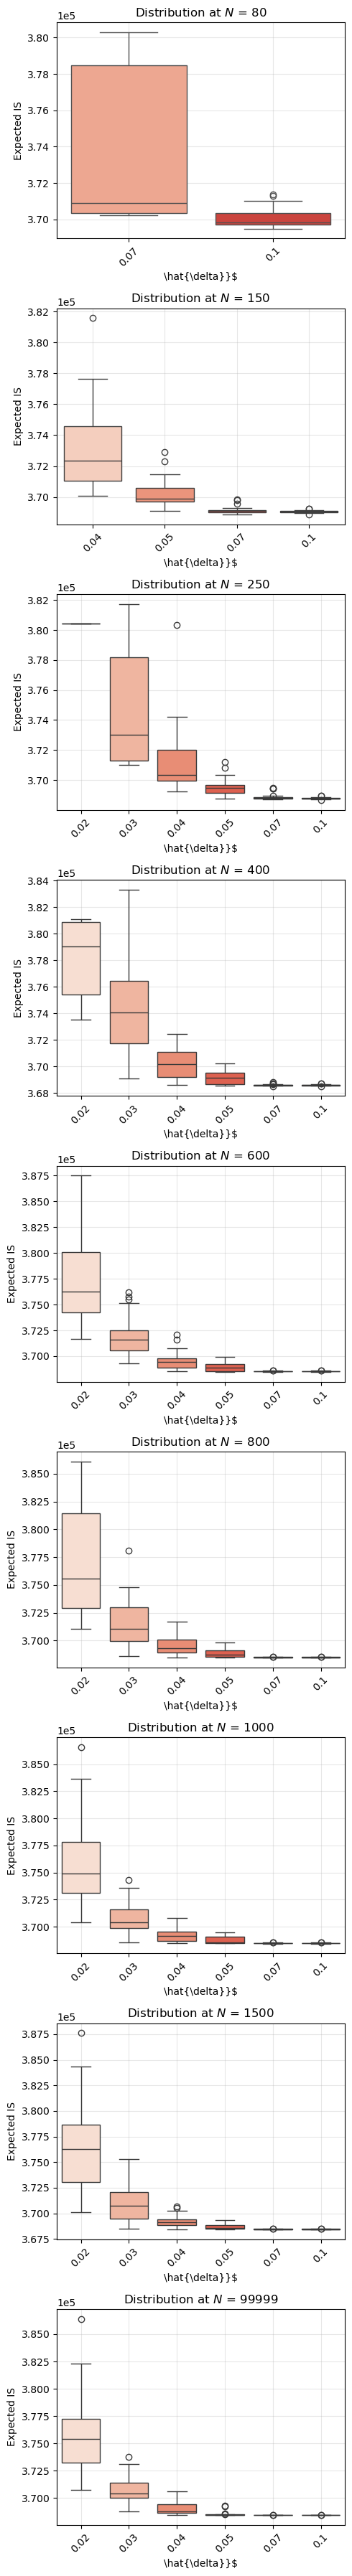

In [11]:

# Create subplots for different chanceThresh values
nTrades_values = df_expected_IS['nTrades'].unique()
fig, axes = plt.subplots(len(nTrades_values), 1, figsize=(5, 4 * len(nTrades_values)))

for i, nTrades in enumerate(nTrades_values):
    # Filter data for specific chanceThresh
    df_filtered = df_expected_IS[df_expected_IS['nTrades'] == nTrades]
    
    # Create boxplot with Blues color palette
    sns.boxplot(data=df_filtered, x='chanceThresh', y='expected_IS', ax=axes[i], palette='Reds')
    
    # Set titles and labels
    axes[i].set_title(f'Distribution at $N$ = {nTrades}')
    axes[i].set_xlabel('\\hat{\\delta}}$')
    axes[i].set_ylabel('Expected IS')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    axes[i].grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

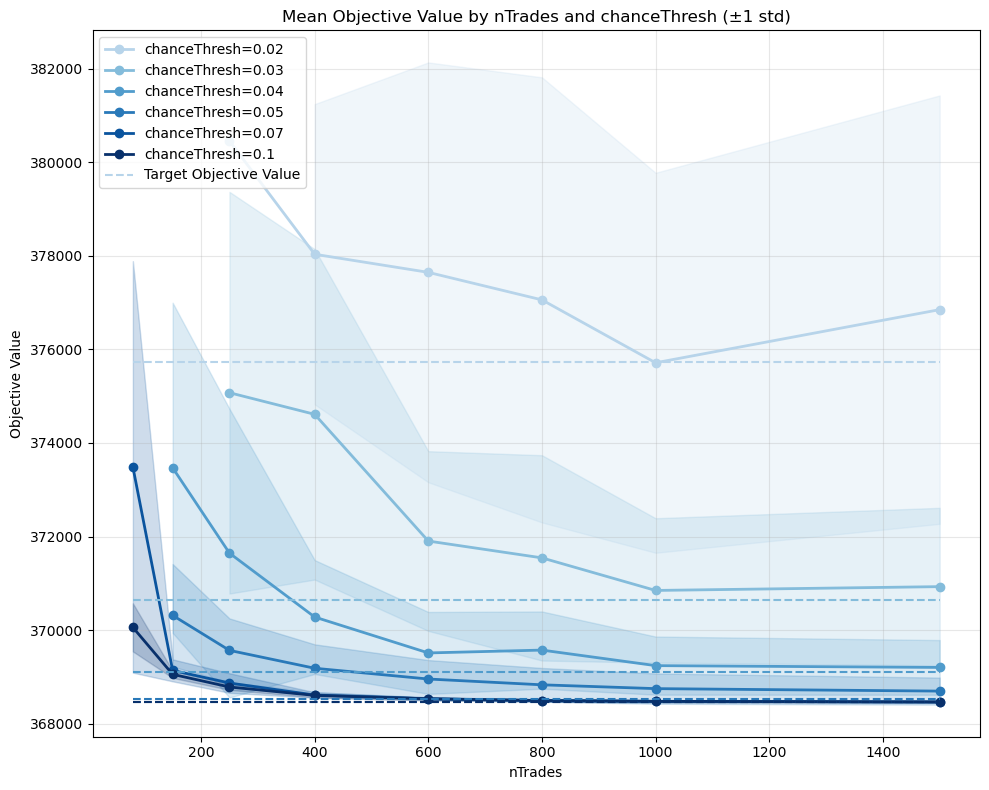

In [12]:
df_IS_filtered = df_expected_IS[df_expected_IS['nTrades']<99999]
df_mean = df_expected_IS.groupby(['nTrades', 'chanceThresh'])['expected_IS'].mean().unstack()
df_std = df_expected_IS.groupby(['nTrades', 'chanceThresh'])['expected_IS'].std().unstack()

# Create the plot
fig, ax = plt.subplots(figsize=(10, 8))
colors_chanceThresh = plt.cm.Blues(np.linspace(0.3, 1, len(df_mean.columns)))
# Plot mean lines with markers
for col, color in zip(df_mean.columns, colors_chanceThresh):
    ax.plot(df_mean.index[:-1], df_mean[col].iloc[:-1], marker='o', label=f'chanceThresh={col}', linewidth=2, color=color)

    # Add standard deviation bands
    ax.fill_between(df_mean.index[:-1], 
                    df_mean[col].iloc[:-1] - df_std[col].iloc[:-1], 
                    df_mean[col].iloc[:-1] + df_std[col].iloc[:-1], 
                    alpha=0.2, color=color)
ax.hlines(df_mean.iloc[-1], xmin=df_mean.index.min(), xmax=df_mean.index[-2], colors=colors_chanceThresh, linestyles='--', label='Target Objective Value')
ax.set_xlabel('nTrades')
ax.set_ylabel('Objective Value')
ax.set_title('Mean Objective Value by nTrades and chanceThresh (±1 std)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

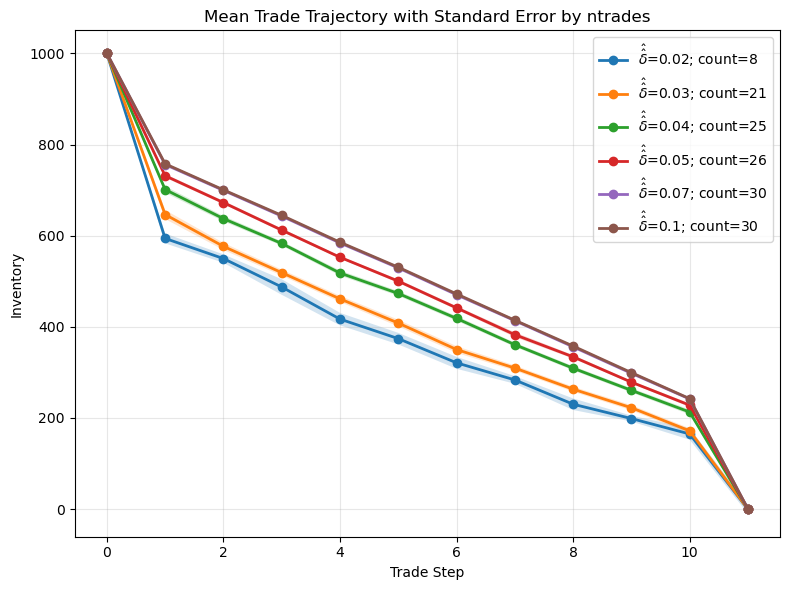

In [13]:
# Group by ntrades and calculate mean and standard error for each trade column
trade_cols = [f'trade_{j}' for j in range(11)]
df_success = combined_df[(combined_df['nScenarios'] == 1000) &
                         (combined_df['status'] == 2) &
                         (combined_df['nTrades'] == 400)]
df_success[trade_cols].multiply(df_success['scale'], axis=0)

plt.figure(figsize=(8, 6))


for chanceTresh, group_data in df_success.groupby('chanceThresh'):

    # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.sum(means) - np.cumsum(means)
    # Plot mean trajectory
    plt.plot(x, y, marker='o', label=f'$\hat{{\hat{{\delta}}}}$={chanceTresh}; count={len(group_data)}', linewidth=2)
    
    # Add standard error bands
    plt.fill_between(x, y - std_errors, y + std_errors, alpha=0.2)

plt.xlabel('Trade Step')
plt.ylabel('Inventory')
plt.title('Mean Trade Trajectory with Standard Error by ntrades')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

/tmp/ipykernel_795631/3702825746.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_success[trade_cols] = df_success[trade_cols].multiply(df_success['scale'], axis=0)


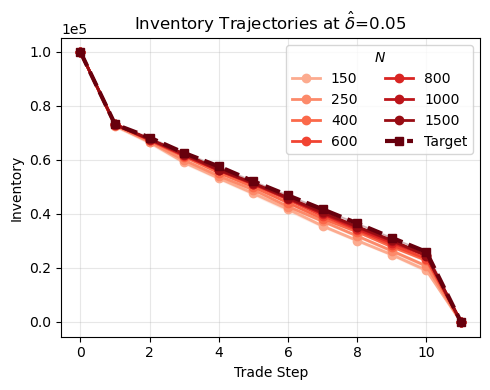

In [14]:
# First plot: Inventory Trajectories
fig, ax = plt.subplots(figsize=(5, 4))
# Group by nTrades and calculate mean and standard error for each trade column
trade_cols = [f'trade_{j}' for j in range(11)]
# Define a color palette

chanceThresh = 0.05
df_success = combined_df[(combined_df['status'] == 2) &
                         (combined_df['chanceThresh'] == chanceThresh)]
df_success[trade_cols] = df_success[trade_cols].multiply(df_success['scale'], axis=0)
colors_ntrades = plt.cm.Reds(np.linspace(0.3, 1, len(df_success['nTrades'].unique())))
# Define different color palette
for i, (nTrades, group_data) in enumerate(df_success.groupby('nTrades')):
    # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.sum(means) - np.cumsum(means)
    
    # Plot mean trajectory
    N = 'Target' if nTrades == 99999 else nTrades
    
    if N == 'Target':
        # Special styling for Target
        ax.plot(x, y, marker='s', label=f'{N}', 
                linewidth=3, linestyle='--', color=colors_ntrades[-1])
        ax.fill_between(x, y - std_errors, y + std_errors, alpha=0.2, color=colors_ntrades[-1])
    else:
        # Regular styling
        ax.plot(x, y, marker='o', label=f'{N}', 
                linewidth=2, color=colors_ntrades[i])
        ax.fill_between(x, y - std_errors, y + std_errors, alpha=0.2, color=colors_ntrades[i])

ax.set_ylabel('Inventory')
ax.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
ax.set_title(f'Inventory Trajectories at $\hat{{\delta}}$={chanceThresh:.2f}')
ax.set_xlabel('Trade Step')
ax.legend(title=r"$N$", ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

/tmp/ipykernel_795631/4003798933.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_success[trade_cols] = df_success[trade_cols].multiply(df_success['scale'], axis=0)


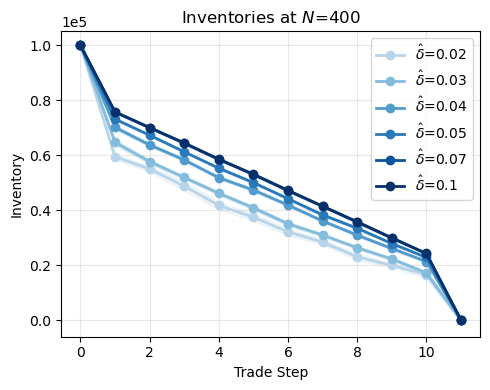

In [15]:
# Second plot: Trade Trajectory
fig, ax = plt.subplots(figsize=(5, 4))

trade_cols = [f'trade_{j}' for j in range(11)]
n_trades = 400
df_success = combined_df[(combined_df['status'] == 2) &
                         (combined_df['nTrades'] == n_trades)]
df_success[trade_cols] = df_success[trade_cols].multiply(df_success['scale'], axis=0)

# Define different color palettes for each subplot
colors_thresh = plt.cm.Blues(np.linspace(0.3, 1, df_success['chanceThresh'].nunique()))

for i, (chanceTresh, group_data) in enumerate(df_success.groupby('chanceThresh')):
    # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.sum(means) - np.cumsum(means)
    # Plot mean trajectory
    ax.plot(x, y, marker='o', label=f"$\hat{{\delta}}$={chanceTresh}", 
            linewidth=2, color=colors_thresh[i])

    # Add standard error bands with matching colors
    ax.fill_between(x, y - std_errors, y + std_errors, alpha=0.2, color=colors_thresh[i])

# Set titles and labels for trade trajectory plot
ax.set_ylabel('Inventory')
ax.set_title(f'Inventories at $N$={n_trades}')
ax.set_xlabel('Trade Step')
ax.legend()
ax.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<Axes: xlabel='chanceThresh'>

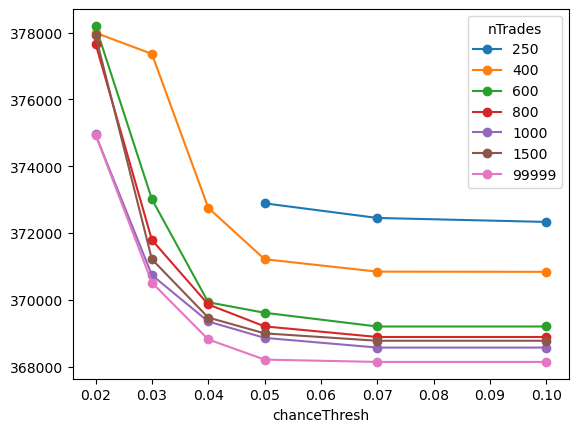

In [13]:
combined_df[(combined_df['nScenarios'] == 1000) & (combined_df['status'] == 2)].groupby(['nTrades', 'chanceThresh'])['obj_val'].mean().unstack().T.plot(marker='o')

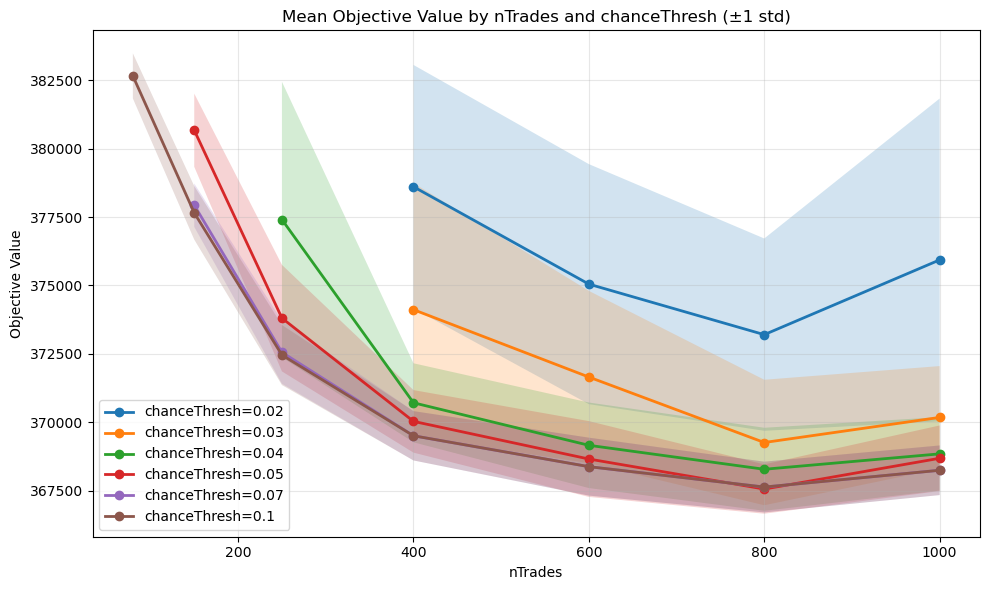

In [ ]:
# Calculate mean and std for objective values
target_obj = combined_df[(combined_df['nTrades'] < 99999)].obj_val.mean()
df_IS_filtered = combined_df[(combined_df['nScenarios'] == 1000) & (combined_df['status'] == 2) & (combined_df['nTrades'] < 99999)]
df_mean = df_IS_filtered.groupby(['nTrades', 'chanceThresh'])['obj_val'].mean().unstack()
df_std = df_IS_filtered.groupby(['nTrades', 'chanceThresh'])['obj_val'].std().unstack()

# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

# Plot mean lines with markers
for col in df_mean.columns:
    ax.plot(df_mean.index, df_mean[col], marker='o', label=f'chanceThresh={col}', linewidth=2)
    
    # Add standard deviation bands
    ax.fill_between(df_mean.index, 
                    df_mean[col] - df_std[col], 
                    df_mean[col] + df_std[col], 
                    alpha=0.2)

ax.set_xlabel('nTrades')
ax.set_ylabel('Objective Value')
ax.set_title('Mean Objective Value by nTrades and chanceThresh (±1 std)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

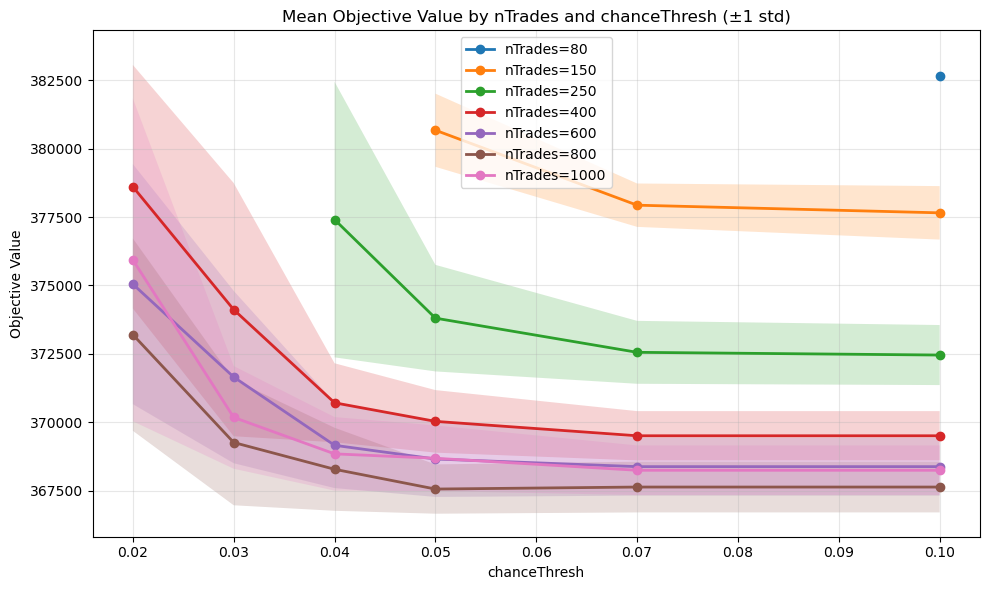

In [ ]:
# Calculate mean and std for objective values
target_obj = combined_df[(combined_df['nTrades'] < 99999)].obj_val.mean()
df_IS_filtered = combined_df[(combined_df['nScenarios'] == 1000) & (combined_df['status'] == 2) & (combined_df['nTrades'] < 99999)]
df_mean = df_IS_filtered.groupby(['nTrades', 'chanceThresh'])['obj_val'].mean().unstack().T
df_std = df_IS_filtered.groupby(['nTrades', 'chanceThresh'])['obj_val'].std().unstack().T

# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

# Plot mean lines with markers
for col in df_mean.columns:
    ax.plot(df_mean.index, df_mean[col], marker='o', label=f'nTrades={col}', linewidth=2)
    
    # Add standard deviation bands
    ax.fill_between(df_mean.index, 
                    df_mean[col] - df_std[col], 
                    df_mean[col] + df_std[col], 
                    alpha=0.2)

ax.set_xlabel('chanceThresh')
ax.set_ylabel('Objective Value')
ax.set_title('Mean Objective Value by nTrades and chanceThresh (±1 std)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

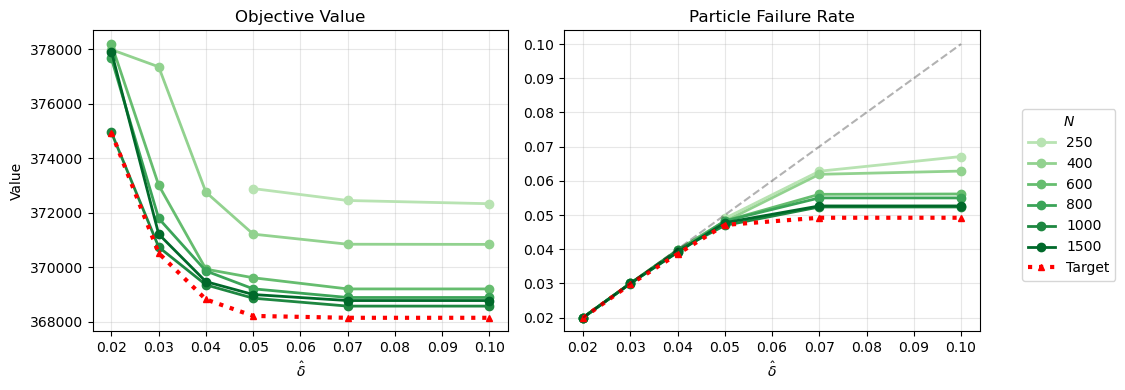

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Create the plots and get data for legend manipulation
df_obj = combined_df[(combined_df['status'] == 2)].groupby(['nTrades', 'chanceThresh'])['obj_val'].mean().unstack().T
df_failure = combined_df[(combined_df['status'] == 2)].groupby(['nTrades', 'chanceThresh'])['failure_rate'].mean().unstack().T

# Rename 99999 column to 'Target' if it exists
if 99999 in df_obj.columns:
    df_obj = df_obj.rename(columns={99999: 'Target'})
if 99999 in df_failure.columns:
    df_failure = df_failure.rename(columns={99999: 'Target'})

# Define a color palette (using seaborn's colorblind-friendly palette)
colors_ntrades = plt.cm.Greens(np.linspace(0.3, 1, len(df_obj.columns)))  # Exclude last color for 'Target'

# Plot the data with custom styling
for i, col in enumerate(df_obj.columns):
    if col == 'Target':
        # Special styling for Target line
        axes[0].plot(df_obj.index, df_obj[col], marker='^', linestyle=':', 
                    linewidth=3, markersize=5, color='red', label=col)
        axes[1].plot(df_failure.index, df_failure[col], marker='^', linestyle=':', 
                    linewidth=3, markersize=5, color='red', label=col)
    else:
        # Regular styling for other lines
        axes[0].plot(df_obj.index, df_obj[col], marker='o', linestyle='-', 
                    linewidth=2, color=colors_ntrades[i], label=col)
        axes[1].plot(df_failure.index, df_failure[col], marker='o', linestyle='-', 
                    linewidth=2, color=colors_ntrades[i], label=col)

# Add the diagonal reference line
axes[1].plot([.02, 0.1], [0.02, 0.1], color='black', linestyle='--', alpha=0.3)

# Set titles and labels
axes[0].set_xlabel(r'$\hat{{\delta}}$')
axes[0].set_ylabel('Value')
axes[0].set_title('Objective Value')
axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel(r'$\hat{{\delta}}$')
axes[1].set_title('Particle Failure Rate')
axes[1].grid(True, alpha=0.3)

# Create a shared legend outside the plots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=10, title=r"$N$")

plt.tight_layout()
plt.show()

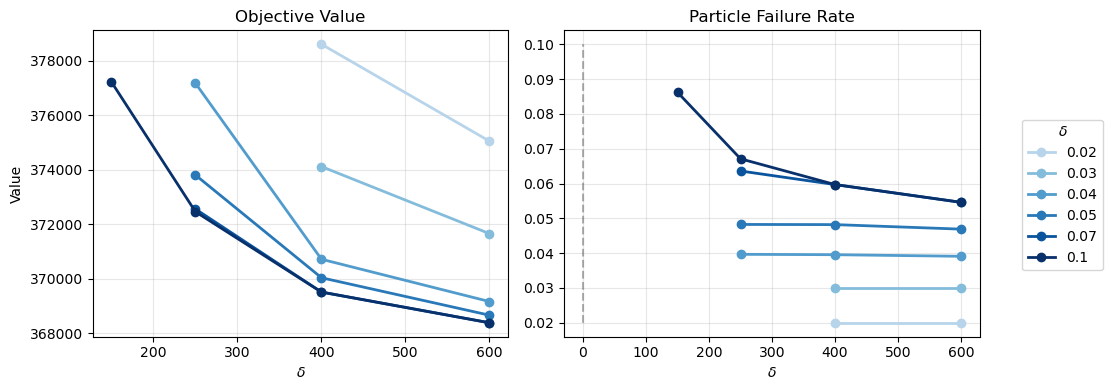

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Create the plots and get data for legend manipulation
df_obj = combined_df[(combined_df['status'] == 2)].groupby(['nTrades', 'chanceThresh'])['obj_val'].mean().unstack().iloc[:-1]
df_failure = combined_df[(combined_df['status'] == 2)].groupby(['nTrades', 'chanceThresh'])['failure_rate'].mean().unstack().iloc[:-1]

# Rename 99999 column to 'Target' if it exists
if 99999 in df_obj.columns:
    df_obj = df_obj.rename(columns={99999: 'Target'})
if 99999 in df_failure.columns:
    df_failure = df_failure.rename(columns={99999: 'Target'})

# Define a color palette (using seaborn's colorblind-friendly palette)
colors_chanceThresh = plt.cm.Blues(np.linspace(0.3, 1, len(df_obj.columns)))  # Exclude last color for 'Target'

# Plot the data with custom styling
for i, col in enumerate(df_obj.columns):
    if col == 'Target':
        # Special styling for Target line
        axes[0].plot(df_obj.index, df_obj[col], marker='^', linestyle=':', 
                    linewidth=3, markersize=5, color='red', label=col)
        axes[1].plot(df_failure.index, df_failure[col], marker='^', linestyle=':', 
                    linewidth=3, markersize=5, color='red', label=col)
    else:
        # Regular styling for other lines
        axes[0].plot(df_obj.index, df_obj[col], marker='o', linestyle='-', 
                    linewidth=2, color=colors_chanceThresh[i], label=col)
        axes[1].plot(df_failure.index, df_failure[col], marker='o', linestyle='-', 
                    linewidth=2, color=colors_chanceThresh[i], label=col)

# Add the diagonal reference line
axes[1].plot([.02, 0.1], [0.02, 0.1], color='black', linestyle='--', alpha=0.3)

# Set titles and labels
axes[0].set_xlabel(r'$\hat{{\delta}}$')
axes[0].set_ylabel('Value')
axes[0].set_title('Objective Value')
axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel(r'$\hat{{\delta}}$')
axes[1].set_title('Particle Failure Rate')
axes[1].grid(True, alpha=0.3)

# Create a shared legend outside the plots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=10, title=r"$\hat{{\delta}}$")

plt.tight_layout()
plt.show()

In [15]:

optimal_rate = combined_df.groupby(['nTrades', 'chanceThresh']).agg({
    'status': [('optimal rate', lambda x: (x == 2).mean())]}).unstack().fillna(0)
optimal_rate.columns = optimal_rate.columns.droplevel(0).droplevel(0)

<Axes: xlabel='chanceThresh', ylabel='nTrades'>

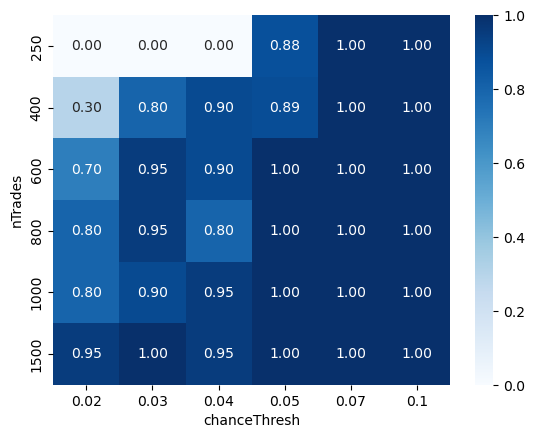

In [16]:
sns.heatmap(optimal_rate.iloc[:-1],
    annot=True, fmt=".2f", cmap='Blues')

/tmp/ipykernel_1914292/173244002.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sns.heatmap(combined_df[combined_df['status'] == 2].groupby(['chanceThresh']).apply(trade_MSE).unstack().T, annot=True, fmt=".2g", cmap='Blues')


<Axes: xlabel='chanceThresh', ylabel='nTrades'>

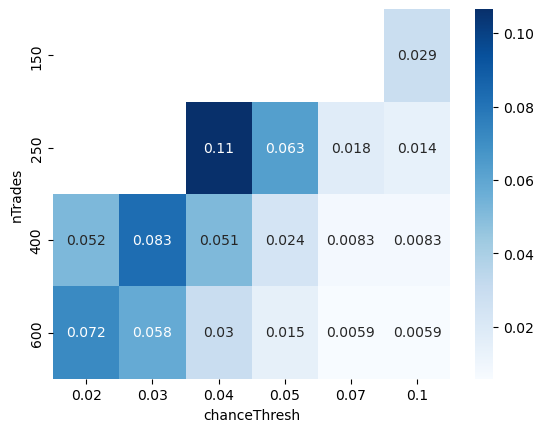

In [13]:
def trade_MSE(df_success):
    true_trades = df_success[df_success['nTrades'] == 99999][trade_cols].mean()
    df_MSE = ((df_success[trade_cols] - true_trades) ** 2).sum(axis=1).groupby(df_success['nTrades'])
    norm = (true_trades ** 2).sum()
    return (df_MSE.mean() / norm).iloc[:-1]
sns.heatmap(combined_df[combined_df['status'] == 2].groupby(['chanceThresh']).apply(trade_MSE).unstack().T, annot=True, fmt=".2g", cmap='Blues')

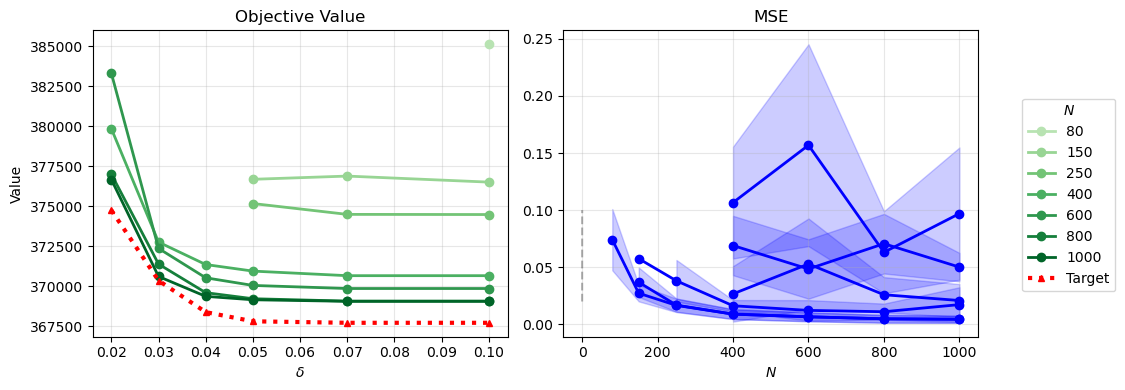

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Create the plots and get data for legend manipulation
df_obj = combined_df[(combined_df['status'] == 2)].groupby(['nTrades', 'chanceThresh'])['obj_val'].mean().unstack()


# Rename 99999 column to 'Target' if it exists
if 99999 in df_obj.columns:
    df_obj = df_obj.rename(columns={99999: 'Target'})
if 99999 in df_failure.columns:
    df_failure = df_failure.rename(columns={99999: 'Target'})

# Define a color palette (using seaborn's colorblind-friendly palette)
colors_ntrades = plt.cm.Greens(np.linspace(0.3, 1, len(df_obj.columns)))  # Exclude last color for 'Target'

# Plot the data with custom styling
for i, col in enumerate(df_obj.columns):
    if col == 'Target':
        # Special styling for Target line
        axes[0].plot(df_obj.index, df_obj[col], marker='^', linestyle=':', 
                    linewidth=3, markersize=5, color='red', label=col)
    else:
        # Regular styling for other lines
        axes[0].plot(df_obj.index, df_obj[col], marker='o', linestyle='-', 
                    linewidth=2, color=colors_ntrades[i], label=col)

trade_cols = [f'trade_{j}' for j in range(11)]
for i, chanceThresh in enumerate(df_obj.index):
    df_success = combined_df[(combined_df['status'] == 2) & (combined_df['chanceThresh'] == chanceThresh)]
    true_trades = df_success[df_success['nTrades'] == 99999][trade_cols].mean()
    df_MSE = ((df_success[trade_cols] - true_trades) ** 2).sum(axis=1).groupby(df_success['nTrades'])
    norm = (true_trades ** 2).sum()
    (df_MSE.mean() / norm).iloc[:-1].plot(marker='o', ax=axes[1], color='blue', label='Mean', linewidth=2)
    axes[1].fill_between(df_MSE.mean().index[:-1], 
                        (df_MSE.mean() - df_MSE.std()).iloc[:-1] / norm, 
                        (df_MSE.mean() + df_MSE.std()).iloc[:-1] / norm, 
                        alpha=0.2, color='blue', label='±1 std')
# Add the diagonal reference line
axes[1].plot([.02, 0.1], [0.02, 0.1], color='black', linestyle='--', alpha=0.3)

# Set titles and labels
axes[0].set_xlabel(r'$\hat{{\delta}}$')
axes[0].set_ylabel('Value')
axes[0].set_title('Objective Value')
axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel(r'$N$')
axes[1].set_title('MSE')
axes[1].grid(True, alpha=0.3)

# Create a shared legend outside the plots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=10, title=r"$N$")

plt.tight_layout()
plt.show()



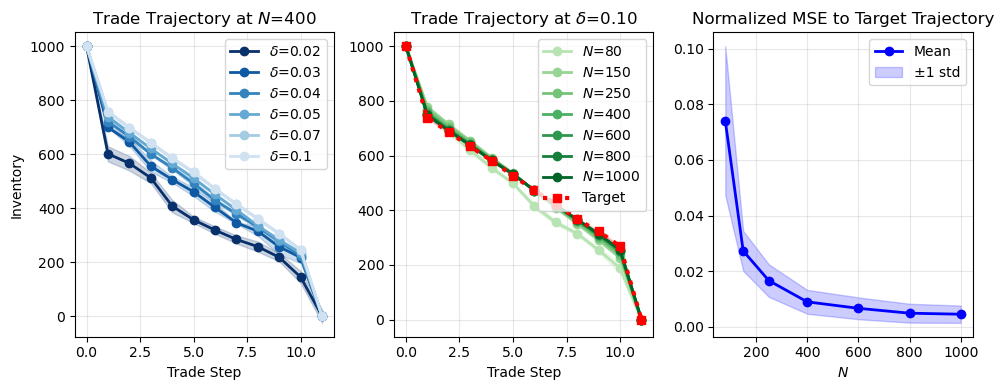

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
# Group by nTrades and calculate mean and standard error for each trade column
trade_cols = [f'trade_{j}' for j in range(11)]
n_trades = 400
df_success = combined_df[(combined_df['status'] == 2) &
                         (combined_df['nTrades'] == n_trades)]
df_success[trade_cols].multiply(df_success['scale'], axis=0)

# Define different color palettes for each subplot
colors_left = plt.cm.Blues(np.linspace(0.2, 1, df_success['chanceThresh'].nunique())[::-1])

for i, (chanceTresh, group_data) in enumerate(df_success.groupby('chanceThresh')):
    # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.sum(means) - np.cumsum(means)
    # Plot mean trajectory with viridis color palette
    axes[0].plot(x, y, marker='o', label=f'$\hat{{\delta}}$={chanceTresh}', 
                linewidth=2, color=colors_left[i])
    
    # Add standard error bands with matching colors
    axes[0].fill_between(x, y - std_errors, y + std_errors, alpha=0.2, color=colors_left[i])

nTrades = 0.1
df_success = combined_df[(combined_df['status'] == 2) &
                         (combined_df['chanceThresh'] == nTrades)]
df_success[trade_cols].multiply(df_success['scale'], axis=0)

# Define different color palette for second subplot
# colors_right = plt.cm.Greens(np.linspace(0.3, 1, df_success['nTrades'].nunique()))
colors_ntrades = colors_ntrades
for i, (nTrades, group_data) in enumerate(df_success.groupby('nTrades')):
    # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.sum(means) - np.cumsum(means)
    
    # Plot mean trajectory
    N = 'Target' if nTrades == 99999 else nTrades
    
    if N == 'Target':
        # Special styling for Target
        axes[1].plot(x, y, marker='s', label=f'{N}', 
                    linewidth=3, linestyle=':', color='red')
        axes[1].fill_between(x, y - std_errors, y + std_errors, alpha=0.2, color='red')
    else:
        # Regular styling with Set2 color palette
        axes[1].plot(x, y, marker='o', label=f'$N$={N}', 
                    linewidth=2, color=colors_ntrades[i])
        axes[1].fill_between(x, y - std_errors, y + std_errors, alpha=0.2, color=colors_ntrades[i])

true_trades = df_success[df_success['nTrades'] == 99999][trade_cols].mean()
df_MSE = ((df_success[trade_cols] - true_trades) ** 2).sum(axis=1).groupby(df_success['nTrades'])
norm = (true_trades ** 2).sum()
(df_MSE.mean() / norm).iloc[:-1].plot(marker='o', ax=axes[2], color='blue', label='Mean', linewidth=2)
axes[2].fill_between(df_MSE.mean().index[:-1], 
                     (df_MSE.mean() - df_MSE.std()).iloc[:-1] / norm, 
                     (df_MSE.mean() + df_MSE.std()).iloc[:-1] / norm, 
                     alpha=0.2, color='blue', label='±1 std')
axes[0].set_ylabel('Inventory')
axes[0].set_title(f'Trade Trajectory at $N$={n_trades}')
axes[1].set_title(f'Trade Trajectory at $\hat{{\delta}}$={nTrades:.2f}')
axes[2].set_title('Normalized MSE to Target Trajectory')
axes[0].set_xlabel('Trade Step')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel('Trade Step')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[2].set_xlabel(r'$N$')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Optimization with progressive Bayesian learning

In [5]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results/20250930_5e-5']

# Combine data from multiple directories0250921_recenter_posteriors_5e-5
all_data = []
for base_dir in base_dirs:
    df = get_mip_info(base_dir)
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

  0%|          | 0/13 [00:00<?, ?it/s]

100%|██████████| 13/13 [00:00<00:00, 346.34it/s]


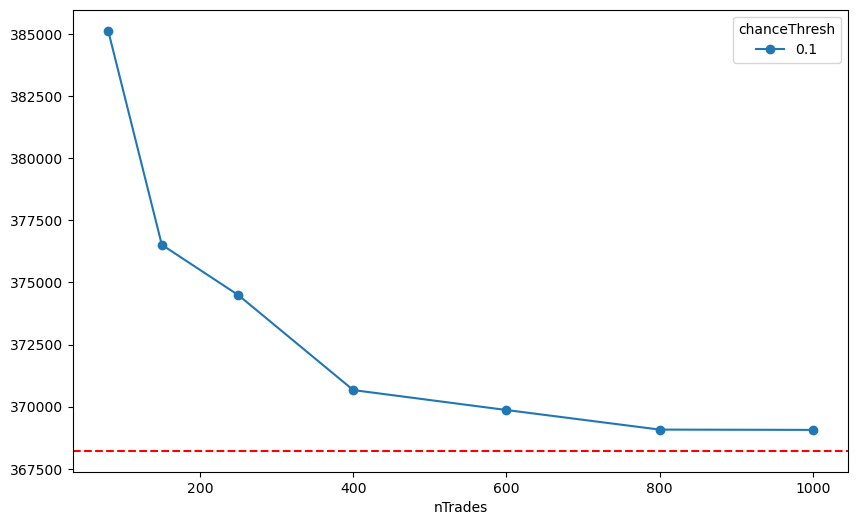

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
combined_df[(combined_df['nScenarios'] == 1000) & (combined_df['status'] == 2)].groupby(['nTrades', 'chanceThresh'])['obj_val'].mean().unstack().iloc[:-1].plot(marker='o', ax=ax)
ax.axhline(combined_df[(combined_df['nScenarios'] == 1000) & (combined_df['status'] == 2)].groupby(['nTrades', 'chanceThresh'])['obj_val'].mean().unstack().iloc[-1].values[0], color='red', linestyle='--', label='Deterministic Obj Val')


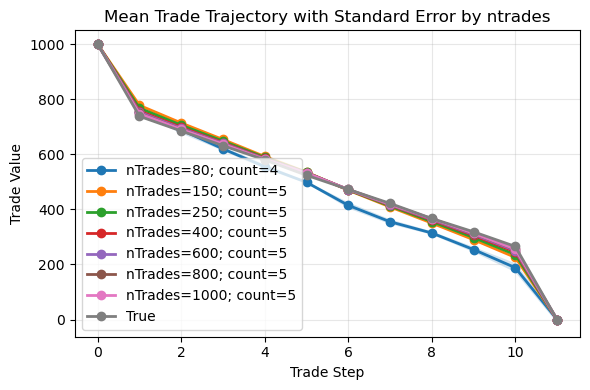

In [ ]:
# Group by ntrades and calculate mean and standard error for each trade column
trade_cols = [f'trade_{j}' for j in range(11)]
df_success = combined_df[(combined_df['chanceThresh'] == 0.10) &
                         (combined_df['status'] == 2)]

plt.figure(figsize=(6, 4))

for nTrades, group_data in df_success.groupby('nTrades'):
    # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.sum(means) - np.cumsum(means)
    # Plot mean trajectory
    line_label = 'True' if nTrades == 99999 else f'nTrades={nTrades}; count={len(group_data)}'
    plt.plot(x, y, marker='o', label=line_label, linewidth=2)

    # Add standard error bands
    plt.fill_between(x, y - std_errors, y + std_errors, alpha=0.2)

plt.xlabel('Trade Step')
plt.ylabel('Trade Value')
plt.title('Mean Trade Trajectory with Standard Error by ntrades')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [29]:
def trade_mse(true_trades, pred_trades):
    return np.mean((true_trades - pred_trades)**2)

In [30]:
true_trades = df_success[df_success['nTrades'] == 99999][trade_cols].mean()

Text(0.5, 1.0, 'Normalized Mean-Squared Error against Trades under no Uncentainty')

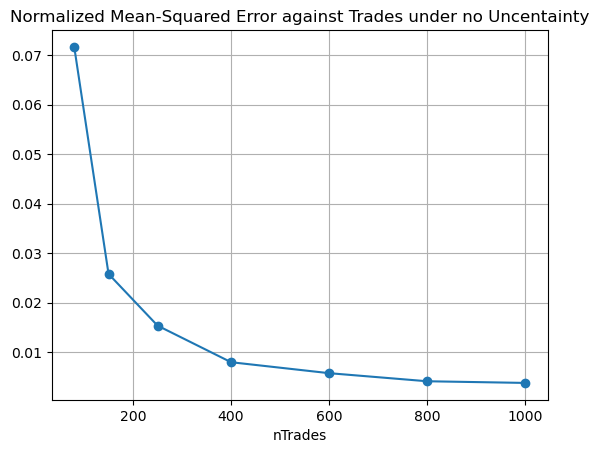

In [31]:
true_trades = df_success[df_success['nTrades'] == 99999][trade_cols].mean()
df_MSE = ((df_success[trade_cols] - true_trades) ** 2).sum(axis=1).groupby(df_success['nTrades']).mean()
norm = (true_trades ** 2).sum()
(df_MSE / norm).iloc[:-1].plot(marker='o')
plt.grid()
plt.title('Normalized Mean-Squared Error against Trades under no Uncentainty')

In [38]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results/20250922_recenter_posteriors_5e-5']

# Combine data from multiple directories0250921_recenter_posteriors_5e-5
all_data = []
for base_dir in base_dirs:
    df = get_mip_info(base_dir)
    all_data.append(df)

combined_df_recenter = pd.concat(all_data, ignore_index=True)

100%|██████████| 36/36 [00:00<00:00, 660.01it/s]


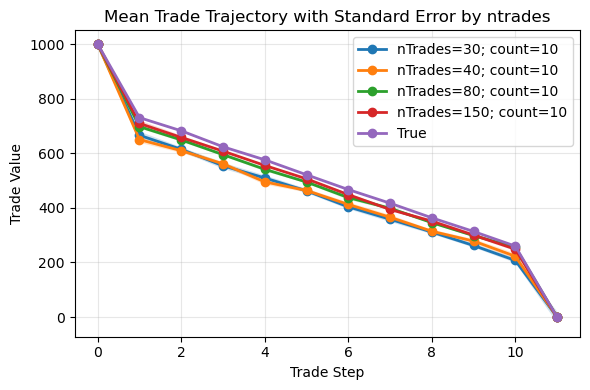

In [ ]:
# Group by ntrades and calculate mean and standard error for each trade column
trade_cols = [f'trade_{j}' for j in range(11)]
df_success_recenter = combined_df_recenter[(combined_df_recenter['chanceThresh'] == 0.05) &
                                   (combined_df_recenter['status'] == 2) &
                                   (combined_df_recenter['scale'] == 100)]

plt.figure(figsize=(6, 4))

for nTrades, group_data in df_success_recenter.groupby('nTrades'):
    if nTrades not in [30, 40, 80, 150, 99999]:
        continue
    # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.sum(means) - np.cumsum(means)
    # Plot mean trajectory
    line_label = 'True' if nTrades == 99999 else f'nTrades={nTrades}; count={len(group_data)}'
    plt.plot(x, y, marker='o', label=line_label, linewidth=2)

    # Add standard error bands
    plt.fill_between(x, y - std_errors, y + std_errors, alpha=0.2)

plt.xlabel('Trade Step')
plt.ylabel('Trade Value')
plt.title('Mean Trade Trajectory with Standard Error by ntrades')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [46]:
true_trades

trade_0     261.789024
trade_1      53.315101
trade_2      53.429692
trade_3      51.517766
trade_4      55.888616
trade_5      51.394492
trade_6      50.814535
trade_7      54.854036
trade_8      48.398970
trade_9      53.109974
trade_10    265.487795
dtype: float64

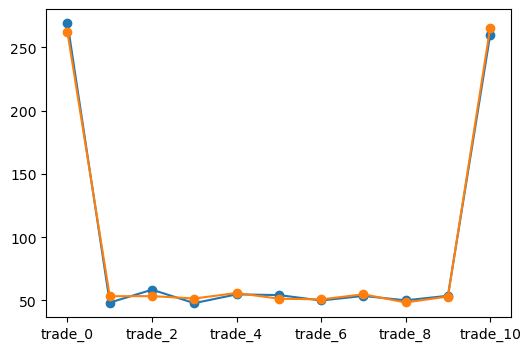

In [47]:
fig, axes = plt.subplots(figsize=(6, 4))
df_success_recenter[df_success_recenter['nTrades'] == 99999][trade_cols].mean().plot(marker='o', ax=axes)
axes.plot(true_trades.values, marker='o')

## Ultimate Plots

In [6]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results/20251017_open_and_close']

# Combine data from multiple directories
all_data = []
for base_dir in base_dirs:
    df = get_mip_info(base_dir)
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)
combined_df['failure_rate'] = (1-combined_df['chance_slack']) * combined_df['chanceThresh'] 
combined_df = combined_df[combined_df['nTrades'] != 800]

100%|██████████| 65/65 [00:00<00:00, 131.41it/s]


In [7]:
combined_df['failure_rate'] = (1-combined_df['chance_slack']) * combined_df['chanceThresh'] 
combined_df.groupby(['nTrades', 'chanceThresh']).agg({
    'obj_val': ['mean', 'std', lambda x: np.quantile(x, 0.95)], 
    'failure_rate': ['mean', 'std'],
    'status': [('optimal rate', lambda x: (x == 2).mean()),
        ('count', 'count')]})

obj_val                             failure_rate  \
                               mean          std     <lambda_0>         mean   
nTrades chanceThresh                                                           
80      0.02                    NaN          NaN            NaN          NaN   
        0.03                    NaN          NaN            NaN          NaN   
        0.04                    NaN          NaN            NaN          NaN   
        0.05          386258.033189   464.366329            NaN     0.050000   
        0.07          386102.078339  4165.253019            NaN     0.069808   
        0.10          381004.296666  1903.365519  384331.924039     0.096800   
150     0.02          384596.542230          NaN            NaN     0.020000   
        0.03          383526.804352  4116.918033            NaN     0.029929   
        0.04          380646.559582  4444.095960  387474.871104     0.039600   
        0.05          376461.080965  2690.698814  380585.826595     0.049433   
        0.07          374137.482423  1569.588220  376256.305690     0.066167   
        0.10          373926.375386  1440.315744  375983.232108     0.072100   
250     0.02          384571.451241  3020.588333            NaN     0.020000   
        0.03          382799.467883  5511.381948            NaN     0.029696   
        0.04          378866.208457  4643.951150  385985.064477     0.039833   
        0.05          375310.406716  2538.771636  379861.352811     0.049133   
        0.07          373465.670310  1527.825966  376007.223903     0.064100   
        0.10          373361.717131  1418.808832  375564.949679     0.066967   
400     0.02          380252.959870  3043.552872            NaN     0.020000   
        0.03          378010.679871  4310.925563            NaN     0.029966   
        0.04          374071.850311  2661.585677  376648.253731     0.039800   
        0.05          372525.435247  1840.086562  375263.137365     0.048667   
        0.07          371688.058592  1419.524428  373710.306951     0.061133   
        0.10          371676.454714  1424.366567  373710.306951     0.062567   
600     0.02          378805.040246  4805.837422            NaN     0.020000   
        0.03          373658.030778  2627.945684  378160.064881     0.029933   
        0.04          371215.424961  1912.535483  374827.764289     0.039733   
        0.05          370499.838515  1584.132175  373371.750652     0.048200   
        0.07          370047.191372  1409.413449  372078.949058     0.056567   
        0.10          370047.191372  1409.413449  372078.949058     0.056633   
1000    0.02          376465.040463  4737.629521            NaN     0.020000   
        0.03          372051.721180  2473.628205  375988.388659     0.030000   
        0.04          370299.414685  1781.389731  373206.852358     0.039400   
        0.05          369677.034544  1535.497454  372280.442547     0.046733   
        0.07          369386.625754  1371.939766  371495.240363     0.052667   
        0.10          369386.625754  1371.939766  371495.240363     0.052667   
1500    0.02          377892.816209  5165.663584            NaN     0.020000   
        0.03          372094.684217  2528.814672  376308.171495     0.029967   
        0.04          370462.348739  1744.586253  373121.140569     0.039267   
        0.05          369816.638595  1463.524070  371971.779354     0.047267   
        0.07          369586.089019  1353.887313  371394.335745     0.052567   
        0.10          369586.089019  1353.887313  371394.335745     0.052567   
99999   0.02          376704.640154  4326.752097            NaN     0.020000   
        0.03          371345.464524  1991.769135  374670.476477     0.029800   
        0.04          369748.340286  1739.954801  372690.538179     0.038933   
        0.05          369172.065036  1503.512383  371533.209291     0.046333   
        0.07          369103.017778  1440.092476  371521.201570     0.048300   
        0.10          369103

In [8]:
def IS_tim(action, posterior_samples, n_steps, total_qty, tau, sigma, spread):
    """
    Pure NumPy implementation of IS_tim_particles.
    Returns realized IS values across posterior scenarios.
    """
    
    n_scenarios = len(posterior_samples['gamma'])
    np.random.seed(42)
    # Gaussian noise: shape (n_scenarios, n_steps+1)
    noise = np.random.normal(0, 1, (n_scenarios, n_steps + 1))
    
    # Extract posterior params
    kappa = np.array(posterior_samples["kappa"])  # (n_scenarios,)
    gamma = np.array(posterior_samples["gamma"])  # (n_scenarios,)
    rho = 2.231  # could also be np.array if sampled
    
    # Precompute action terms
    action = np.asarray(action)
    action_sq_sum = np.sum(action**2)
    action_cumsum = np.cumsum(action)
    inventory = total_qty - action_cumsum  # shape (n_steps+1,)
    
    # Permanent impact
    permanent_impact = 0.5 * gamma * total_qty**2 - 0.5 * gamma * action_sq_sum
    
    # Spread cost (same for all scenarios)
    spread_cost = spread * total_qty
    
    # Temporary impact
    temporary_impact = 0.5 * (gamma + kappa) * action_sq_sum
    
    # Stochastic term: sum_k inventory[k] * noise[p, k]
    stochastic_term = sigma * np.sqrt(tau) * (noise @ inventory)
    
    # Transient impact
    time_idx = np.arange(n_steps + 1)
    # exp(-rho * tau * (k - i)) for k>i
    kernel = np.exp(-rho * tau * (time_idx[None, :] - time_idx[:, None]))
    kernel = np.triu(kernel, k=1)  # zero out k <= i
    
    transient_impact_per_action = action @ (kernel @ action)  # scalar
    transient_impact = kappa * transient_impact_per_action
    
    # IS values per scenario
    IS_exprs = permanent_impact + spread_cost + temporary_impact - stochastic_term + transient_impact
    # print(f'permanent_impact: {permanent_impact}, temporary_impact: {temporary_impact}, stochastic_term: {stochastic_term}, transient_impact: {transient_impact}')
    return IS_exprs

kappa = 5e-5
gamma = 5e-5
sigma = 0.
rho = 2.231
scale= 100
n_scenarios = 1
total_qty = 1e5
n_steps = 10
tau = 0.1
spread = 0
loss_thresh = 4.5e5
posterior_samples = {"gamma": [gamma]*n_scenarios, "kappa": [kappa]*n_scenarios, "rho": [rho]*n_scenarios}

dict_expected_IS = []
dict_p_violation = []
trade_cols = [f'trade_{j}' for j in range(11)]
for (nTrades, chanceThresh), group in tqdm(combined_df.groupby(['nTrades', 'chanceThresh'])):
    trades = group[group['status']==2][trade_cols] * scale
    for idx, row in trades.iterrows():
        IS = IS_tim(np.array(row), posterior_samples, n_steps, total_qty, tau, sigma, spread)
        dict_expected_IS.append({'nTrades': nTrades, 'chanceThresh': chanceThresh, 'expected_IS': IS.mean()})
        dict_p_violation.append({'nTrades': nTrades, 'chanceThresh': chanceThresh, 'p_vio': np.mean(IS > loss_thresh)})
df_expected_IS = pd.DataFrame(dict_expected_IS)

  0%|          | 0/48 [00:00<?, ?it/s]

100%|██████████| 48/48 [00:00<00:00, 113.30it/s]


/tmp/ipykernel_3416643/1999210140.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_success[trade_cols] = df_success[trade_cols].multiply(df_success['scale'], axis=0)
/tmp/ipykernel_3416643/1999210140.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='chanceThresh', y='expected_IS', ax=ax3, palette=colors_thresh)
/tmp/ipykernel_3416643/1999210140.py:59: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  sns.boxplot(data=df_filtered, x='chanceThresh', y='expected_IS', ax=ax3, palette

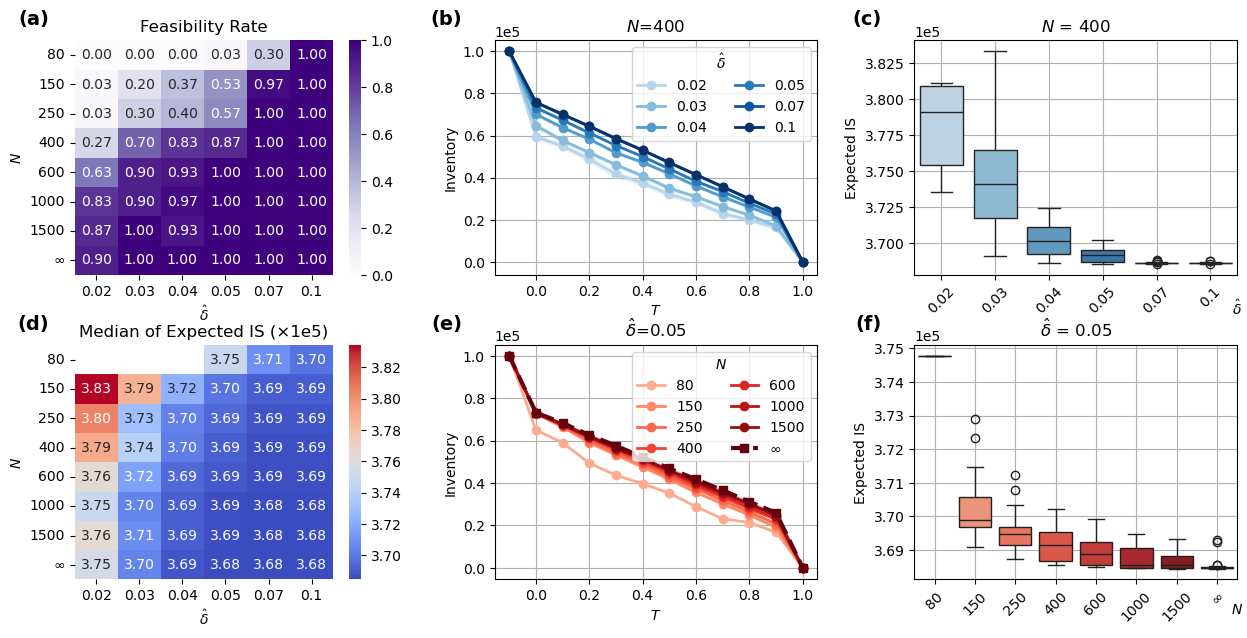

In [9]:
# Combined figure with all six plots from Ultimate Plots section
fig, axes = plt.subplots(2, 3, figsize=(15, 7), 
                        gridspec_kw={'hspace': 0.3, 'wspace': 0.3})

# Flatten axes for easier indexing
ax1, ax2, ax3 = axes[0, :]  # Top row
ax4, ax5, ax6 = axes[1, :]  # Bottom row

# Plot 1: Feasibility Heatmap (top-left)
optimal_rate = combined_df.groupby(['nTrades', 'chanceThresh']).agg({
    'status': [('optimal rate', lambda x: (x == 2).mean())]}).unstack().fillna(0)
optimal_rate.columns = optimal_rate.columns.droplevel(0).droplevel(0)
sns.heatmap(optimal_rate, annot=True, fmt=".2f", cmap='Purples', ax=ax1)

yticklabels = ax1.get_yticklabels()
yticklabels[-1].set_text(r'$\infty$')
ax1.set_yticklabels(yticklabels)
ax1.set_title('Feasibility Rate')
ax1.set_ylabel(r'$N$')
ax1.set_xlabel(r'$\hat{{\delta}}$')

# Plot 2: Inventory Trajectories (varying delta at fixed N) (top-middle)
trade_cols = [f'trade_{j}' for j in range(11)]
n_trades = 400
df_success = combined_df[(combined_df['status'] == 2) &
                         (combined_df['nTrades'] == n_trades)]
df_success[trade_cols] = df_success[trade_cols].multiply(df_success['scale'], axis=0)
colors_thresh = plt.cm.Blues(np.linspace(0.3, 1, df_success['chanceThresh'].nunique()))

for i, (chanceThresh, group_data) in enumerate(df_success.groupby('chanceThresh')):
    means = [0]
    std_errors = [0]
    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(-0.1, 1.01, 0.1)
    y = np.sum(means) - np.cumsum(means)
    ax2.plot(x, y, marker='o',
            linewidth=2, color=colors_thresh[i], label=chanceThresh)
    ax2.fill_between(x, y - std_errors, y + std_errors, alpha=0.2, color=colors_thresh[i])

ax2.set_ylabel('Inventory')
ax2.set_xlabel(r'$T$')
ax2.set_title(f'$N$={n_trades}')
ax2.legend(title=r"$\hat{{\delta}}$", fontsize=10, ncol=2)
ax2.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
ax2.grid(True)

# Plot 3: Expected IS Boxplot (fixed N) (top-right) 
nTrades = 400
df_filtered = df_expected_IS[df_expected_IS['nTrades'] == nTrades]
sns.boxplot(data=df_filtered, x='chanceThresh', y='expected_IS', ax=ax3, palette=colors_thresh)

ax3.set_title(f'$N$ = {nTrades}')
ax3.set_xlabel(r'$\hat{{\delta}}$')
ax3.xaxis.set_label_coords(1, -0.1)  # Move x-label to rightmost position

ax3.set_ylabel('Expected IS')
ax3.tick_params(axis='x', rotation=45)
ax3.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
ax3.grid(True)

# Plot 4: Expected IS Heatmap (bottom-left)
df_heatmap_data = df_expected_IS.groupby(['nTrades', 'chanceThresh'])['expected_IS'].median().unstack()
df_scaled = df_heatmap_data * 1e-5
sns.heatmap(df_scaled, annot=True, fmt=".2f", cmap="coolwarm", ax=ax4)

yticklabels = ax4.get_yticklabels()
yticklabels[-1].set_text(r'$\infty$')
ax4.set_yticklabels(yticklabels)
ax4.set_xlabel(r'$\hat{{\delta}}$')
ax4.set_ylabel(r'$N$')
ax4.set_title('Median of Expected IS (×1e5)')

# Plot 5: Inventory Trajectories (varying N at fixed delta) (bottom-middle)
chanceThresh = 0.05
df_success = combined_df[(combined_df['status'] == 2) &
                         (combined_df['chanceThresh'] == chanceThresh)]
df_success[trade_cols] = df_success[trade_cols].multiply(df_success['scale'], axis=0)
colors_ntrades = plt.cm.Reds(np.linspace(0.3, 1, len(df_success['nTrades'].unique())))

for i, (nTrades, group_data) in enumerate(df_success.groupby('nTrades')):
    means = [0]
    std_errors = [0]
    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x =np.arange(-0.1, 1.01, 0.1)
    y = np.sum(means) - np.cumsum(means)

    N = r'$\infty$' if nTrades == 99999 else nTrades
    if N == r'$\infty$':
        ax5.plot(x, y, marker='s', label=f'{N}', 
                linewidth=3, linestyle='--', color=colors_ntrades[-1])
        ax5.fill_between(x, y - std_errors, y + std_errors, alpha=0.2, color=colors_ntrades[-1])
    else:
        ax5.plot(x, y, marker='o', label=f'{N}', 
                linewidth=2, color=colors_ntrades[i])
        ax5.fill_between(x, y - std_errors, y + std_errors, alpha=0.2, color=colors_ntrades[i])

ax5.set_ylabel('Inventory')
ax5.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
ax5.set_title(f'$\hat{{\delta}}$={chanceThresh:.2f}')
ax5.set_xlabel(r'$T$')

ax5.legend(title=r"$N$", fontsize=10, ncol=2)
ax5.grid(True)

# Plot 6: Expected IS Boxplot (fixed delta) (bottom-right)
chanceThresh = 0.05
df_filtered = df_expected_IS[df_expected_IS['chanceThresh'] == chanceThresh]
sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=ax6, palette=colors_ntrades)

ax6.set_title(f'$\\hat{{\\delta}}$ = {chanceThresh}')
ax6.set_xlabel(r'$N$')
ax6.xaxis.set_label_coords(1, -0.1)  # Move x-label to rightmost position
ax6.set_ylabel('Expected IS')
ax6.tick_params(axis='x', rotation=45)
ax6.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
ax6.grid(True)

xticklabels = ax6.get_xticklabels()
if len(xticklabels) > 0:
    xticklabels[-1].set_text(r"$\infty$")
    ax6.set_xticklabels(xticklabels)

# Add subplot labels
for i, ax in enumerate([ax1, ax2, ax3, ax4, ax5, ax6]):
    ax.text(-0.1, 1.05, f'({chr(97+i)})', transform=ax.transAxes, 
            fontsize=14, fontweight='bold', va='bottom', ha='right')

plt.tight_layout()
plt.savefig('../plots/combined_ultimate_plots.pdf', bbox_inches='tight', dpi=300)
plt.show()

/tmp/ipykernel_984224/1915281512.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_success[trade_cols] = df_success[trade_cols].multiply(df_success['scale'], axis=0)


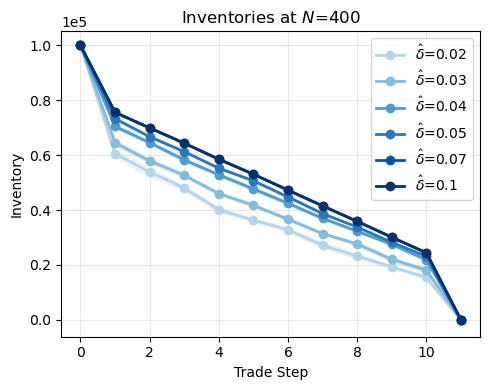

In [5]:
# Second plot: Trade Trajectory
fig, ax = plt.subplots(figsize=(5, 4))

trade_cols = [f'trade_{j}' for j in range(11)]
n_trades = 400
df_success = combined_df[(combined_df['status'] == 2) &
                         (combined_df['nTrades'] == n_trades)]
df_success[trade_cols] = df_success[trade_cols].multiply(df_success['scale'], axis=0)

# Define different color palettes for each subplot
colors_thresh = plt.cm.Blues(np.linspace(0.3, 1, df_success['chanceThresh'].nunique()))

for i, (chanceTresh, group_data) in enumerate(df_success.groupby('chanceThresh')):
    # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.sum(means) - np.cumsum(means)
    # Plot mean trajectory
    ax.plot(x, y, marker='o', label=f"$\hat{{\delta}}$={chanceTresh}", 
            linewidth=2, color=colors_thresh[i])

    # Add standard error bands with matching colors
    ax.fill_between(x, y - std_errors, y + std_errors, alpha=0.2, color=colors_thresh[i])

# Set titles and labels for trade trajectory plot
ax.set_ylabel('Inventory')
ax.set_title(f'Inventories at $N$={n_trades}')
ax.set_xlabel('Trade Step')
ax.legend()
ax.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../plots/inventories.pdf', bbox_inches='tight')
plt.show()

/tmp/ipykernel_984224/1711966219.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_success[trade_cols] = df_success[trade_cols].multiply(df_success['scale'], axis=0)


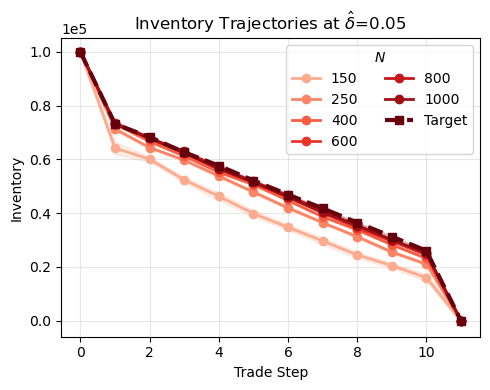

In [ ]:
# First plot: Inventory Trajectories
fig, ax = plt.subplots(figsize=(5, 4))
# Group by nTrades and calculate mean and standard error for each trade column
trade_cols = [f'trade_{j}' for j in range(11)]
# Define a color palette

chanceThresh = 0.05
df_success = combined_df[(combined_df['status'] == 2) &
                         (combined_df['chanceThresh'] == chanceThresh)]
df_success[trade_cols] = df_success[trade_cols].multiply(df_success['scale'], axis=0)
colors_ntrades = plt.cm.Reds(np.linspace(0.3, 1, len(df_success['nTrades'].unique())))
# Define different color palette
for i, (nTrades, group_data) in enumerate(df_success.groupby('nTrades')):
    # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.sum(means) - np.cumsum(means)
    
    # Plot mean trajectory
    N = 'Target' if nTrades == 99999 else nTrades
    
    if N == 'Target':
        # Special styling for Target
        ax.plot(x, y, marker='s', label=f'{N}', 
                linewidth=3, linestyle='--', color=colors_ntrades[-1])
        ax.fill_between(x, y - std_errors, y + std_errors, alpha=0.2, color=colors_ntrades[-1])
    else:
        # Regular styling
        ax.plot(x, y, marker='o', label=f'{N}', 
                linewidth=2, color=colors_ntrades[i])
        ax.fill_between(x, y - std_errors, y + std_errors, alpha=0.2, color=colors_ntrades[i])

ax.set_ylabel('Inventory')
ax.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
ax.set_title(f'Inventory Trajectories at $\hat{{\delta}}$={chanceThresh:.2f}')
ax.set_xlabel('Trade Step')
ax.legend(title=r"$N$", ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../plots/inventories_N.pdf', bbox_inches='tight')
plt.show()

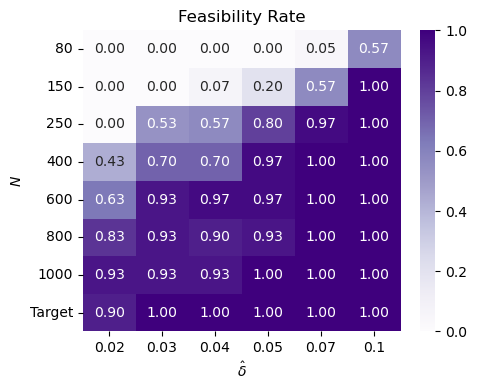

In [7]:
# First plot: Heatmap
fig, ax = plt.subplots(figsize=(5, 4))

optimal_rate = combined_df.groupby(['nTrades', 'chanceThresh']).agg({
    'status': [('optimal rate', lambda x: (x == 2).mean())]}).unstack().fillna(0)
optimal_rate.columns = optimal_rate.columns.droplevel(0).droplevel(0)
sns.heatmap(optimal_rate, annot=True, fmt=".2f", cmap='Purples', ax=ax)

yticklabels = ax.get_yticklabels()
yticklabels[-1].set_text('Target')
ax.set_yticklabels(yticklabels);
ax.set_title('Feasibility Rate')
ax.set_xlabel(r'$\hat{{\delta}}$')
ax.set_ylabel(r'$N$')

plt.tight_layout()
plt.savefig('../plots/feasibility_heatmap.pdf', bbox_inches='tight')
plt.show()

# # Second plot: Particle Failure Rate
# fig, ax = plt.subplots(figsize=(5, 4))

# df_failure = combined_df[(combined_df['status'] == 2)].groupby(['nTrades', 'chanceThresh'])['failure_rate'].mean().unstack().T

# # Rename 99999 column to 'Target' if it exists
# if 99999 in df_failure.columns:
#     df_failure = df_failure.rename(columns={99999: 'Target'})

# # Define color palette for failure rate plot
# colors_ntrades = plt.cm.Reds(np.linspace(0.3, 1, len(df_failure.columns)))

# # Plot the failure rate data
# for i, col in enumerate(df_failure.columns):
#     if col == 'Target':
#         # Special styling for Target line
#         ax.plot(df_failure.index, df_failure[col], marker='^', linestyle='--', 
#                 linewidth=3, markersize=5, color=colors_ntrades[-1], label=col)
#     else:
#         # Regular styling for other lines
#         ax.plot(df_failure.index, df_failure[col], marker='o', linestyle='-', 
#                 linewidth=2, color=colors_ntrades[i], label=col)

# # Add the diagonal reference line
# ax.plot([.02, 0.1], [0.02, 0.1], color='black', linestyle=':', alpha=0.3)

# ax.set_xlabel(r'$\hat{{\delta}}$')
# ax.set_ylabel('Value')
# ax.set_title('Particle Failure Rate')
# ax.grid(True, alpha=0.3)
# ax.legend(title=r"$N$")

# plt.tight_layout()
# plt.savefig('../plots/particle_failure_rate.pdf', bbox_inches='tight')
# plt.show()

<Axes: xlabel='nTrades', ylabel='expected_IS'>

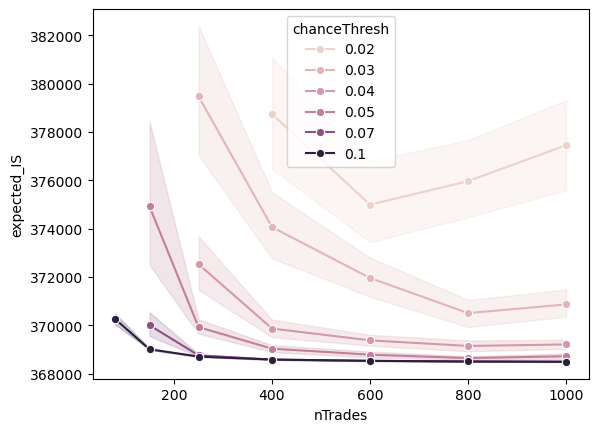

In [ ]:


sns.lineplot(data=df_expected_IS[df_expected_IS['nTrades']<99999], x='nTrades', y='expected_IS', hue='chanceThresh', marker='o')

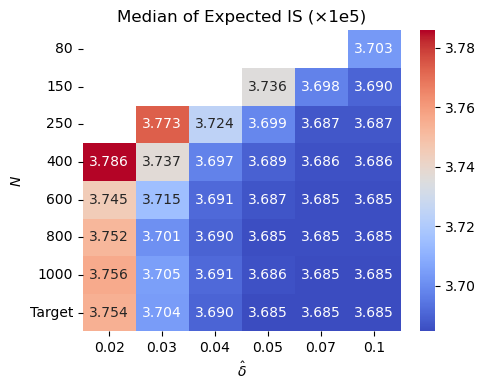

In [15]:
plt.figure(figsize=(5, 4))

# Scale the data by 1e-5 for display
df_heatmap_data = df_expected_IS.groupby(['nTrades', 'chanceThresh'])['expected_IS'].median().unstack()
df_scaled = df_heatmap_data * 1e-5

ax = sns.heatmap(df_scaled, annot=True, fmt=".3f", cmap="coolwarm")

# Get current y-tick labels and modify the last one
yticklabels = ax.get_yticklabels()
yticklabels[-1].set_text('Target')
ax.set_yticklabels(yticklabels);
ax.set_xlabel(r'$\hat{{\delta}}$')
ax.set_ylabel(r'$N$')
ax.set_title('Median of Expected IS (×1e5)')
plt.tight_layout()
plt.savefig('../plots/IS_heatmap.pdf', bbox_inches='tight')
plt.show()

/tmp/ipykernel_3233573/1155358048.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=ax, palette=colors_ntrades)
/tmp/ipykernel_3233573/1155358048.py:10: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=ax, palette=colors_ntrades)
/tmp/ipykernel_3233573/1155358048.py:10: UserWarning: The palette list has more values (8) than needed (7), which may not be intended.
  sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=ax, palette=colors_ntrades)
/tmp/ipykernel_3233573/1155358048.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xtick

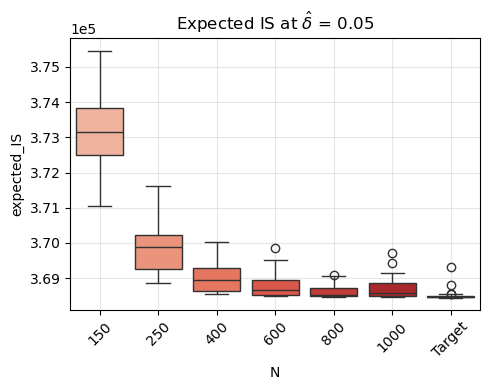

In [ ]:
# ...existing code...
# Create subplots for different chanceThresh values
chanceThresh = 0.05
fig, ax = plt.subplots(1, 1, figsize=(5, 4))

# Filter data for specific chanceThresh
df_filtered = df_expected_IS[df_expected_IS['chanceThresh'] == chanceThresh]

# Create boxplot with Blues color palette
sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=ax, palette=colors_ntrades)

# Set titles and labels
ax.set_title(f'Expected IS at $\\hat{{\\delta}}$ = {chanceThresh}')
ax.set_xlabel('N')
ax.tick_params(axis='x', rotation=45)
ax.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
ax.grid(True, alpha=0.3)

# Get current x-tick labels and modify the last one to 'Target'
xticklabels = ax.get_xticklabels()
if len(xticklabels) > 0:
    xticklabels[-1].set_text('Target')
    ax.set_xticklabels(xticklabels)

plt.tight_layout()
plt.savefig('../plots/expected_IS_boxplot_delta5.pdf', bbox_inches='tight')
plt.show()

/tmp/ipykernel_3233573/2310550497.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=axes[i], palette='Blues')
/tmp/ipykernel_3233573/2310550497.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(xticklabels)
/tmp/ipykernel_3233573/2310550497.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=axes[i], palette='Blues')
/tmp/ipykernel_3233573/2310550497.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLo

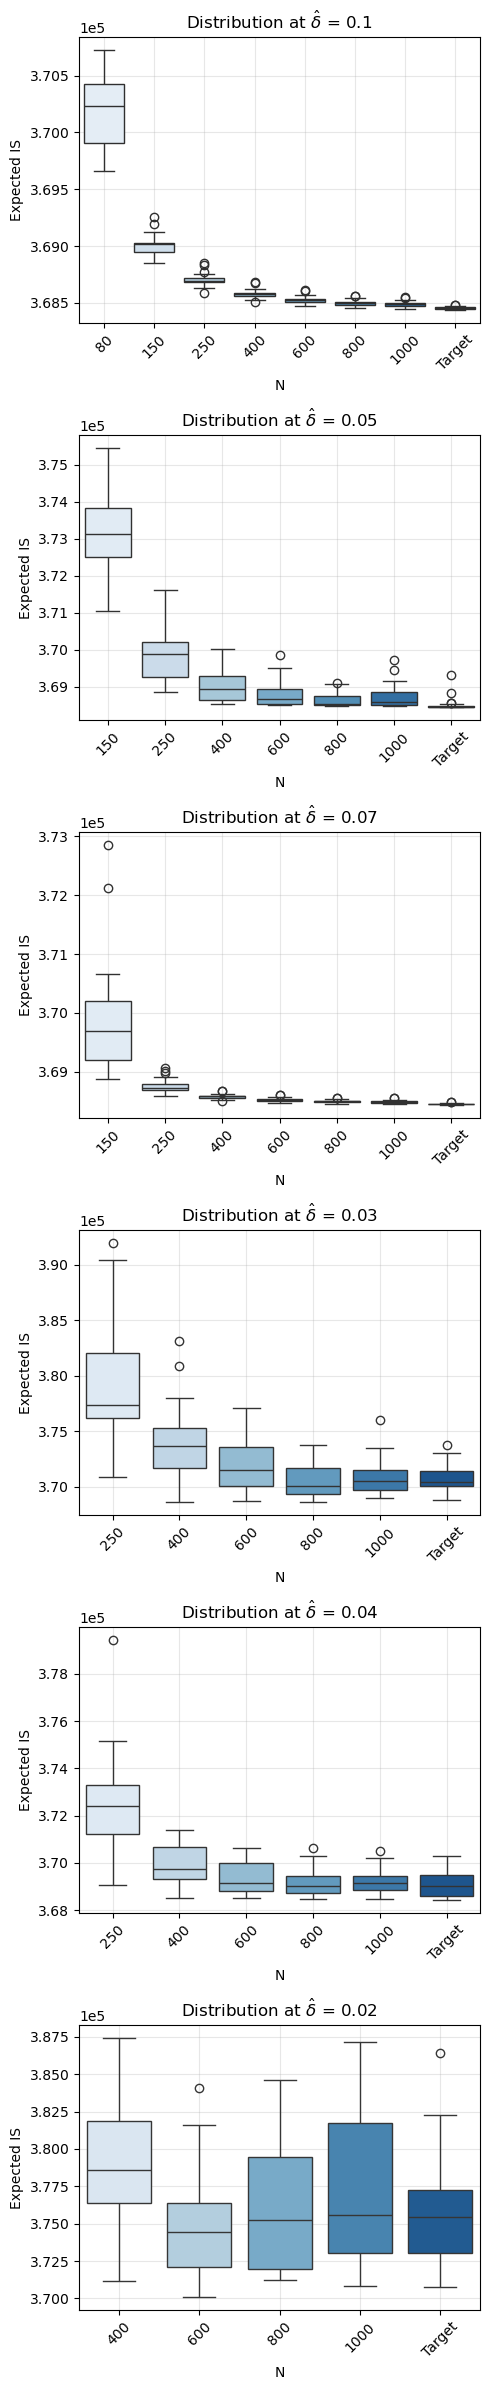

In [ ]:
# ...existing code...
# Create subplots for different chanceThresh values
nTrades_values = df_expected_IS['chanceThresh'].unique()
fig, axes = plt.subplots(len(nTrades_values), 1, figsize=(5, 4 * len(nTrades_values)))

for i, nTrades in enumerate(nTrades_values):
    # Filter data for specific chanceThresh
    df_filtered = df_expected_IS[df_expected_IS['chanceThresh'] == nTrades]
    
    # Create boxplot with Blues color palette
    sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=axes[i], palette='Blues')
    
    # Set titles and labels
    axes[i].set_title(f'Distribution at $\\hat{{\\delta}}$ = {nTrades}')
    axes[i].set_xlabel('N')
    axes[i].set_ylabel('Expected IS')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    axes[i].grid(True, alpha=0.3)
    
    # Get current x-tick labels and modify the last one to 'Target'
    xticklabels = axes[i].get_xticklabels()
    if len(xticklabels) > 0:
        xticklabels[-1].set_text('Target')
        axes[i].set_xticklabels(xticklabels)

plt.tight_layout()
plt.show()

In [14]:
1-np.exp(-1000*0.05**2/2)

np.float64(0.71349520313981)

/tmp/ipykernel_1221195/359280172.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='chanceThresh', y='expected_IS', ax=axes[i], palette='Blues')
/tmp/ipykernel_1221195/359280172.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(xticklabels)
/tmp/ipykernel_1221195/359280172.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='chanceThresh', y='expected_IS', ax=axes[i], palette='Blues')
/tmp/ipykernel_1221195/359280172.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a F

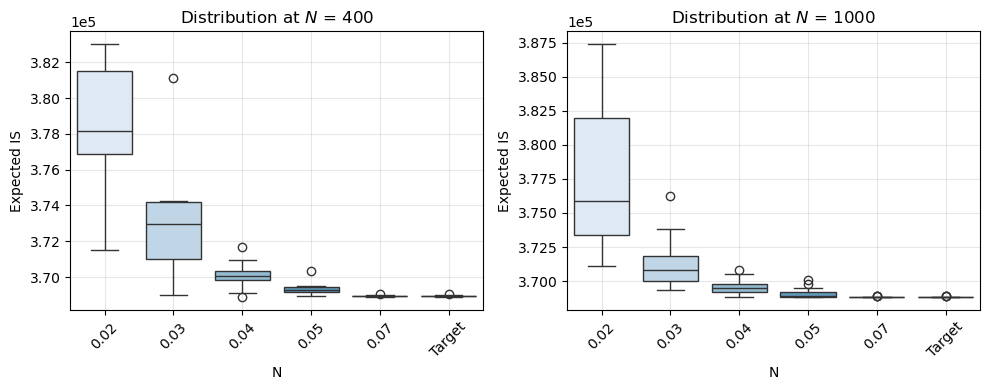

In [ ]:
# ...existing code...
# Create subplots for different chanceThresh values
nTrades_values = [400, 1000]
fig, axes = plt.subplots(1, len(nTrades_values), figsize=(5*len(nTrades_values), 4))

for i, nTrades in enumerate(nTrades_values):
    # Filter data for specific chanceThresh
    df_filtered = df_expected_IS[df_expected_IS['nTrades'] == nTrades]
    
    # Create boxplot with Blues color palette
    sns.boxplot(data=df_filtered, x='chanceThresh', y='expected_IS', ax=axes[i], palette='Blues')
    
    # Set titles and labels
    axes[i].set_title(f'Distribution at $N$ = {nTrades}')
    axes[i].set_xlabel('N')
    axes[i].set_ylabel('Expected IS')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    axes[i].grid(True, alpha=0.3)
    
    # Get current x-tick labels and modify the last one to 'Target'
    xticklabels = axes[i].get_xticklabels()
    if len(xticklabels) > 0:
        xticklabels[-1].set_text('Target')
        axes[i].set_xticklabels(xticklabels)

plt.tight_layout()
plt.show()

/tmp/ipykernel_3233573/2616681354.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=axes[i], palette=colors_ntrades)
/tmp/ipykernel_3233573/2616681354.py:11: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=axes[i], palette=colors_ntrades)
/tmp/ipykernel_3233573/2616681354.py:11: UserWarning: The palette list has more values (8) than needed (7), which may not be intended.
  sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=axes[i], palette=colors_ntrades)
/tmp/ipykernel_3233573/2616681354.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

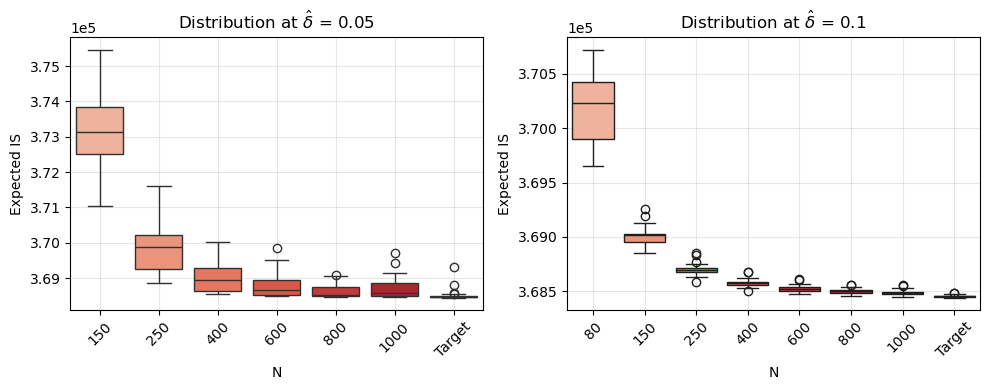

In [52]:
# ...existing code...
# Create subplots for different chanceThresh values
chanceThresh_values = [0.05, 0.1]
fig, axes = plt.subplots(1, len(chanceThresh_values), figsize=(10, 4))

for i, chanceThresh in enumerate(chanceThresh_values):
    # Filter data for specific chanceThresh
    df_filtered = df_expected_IS[df_expected_IS['chanceThresh'] == chanceThresh]

    # Create boxplot with Blues color palette
    sns.boxplot(data=df_filtered, x='nTrades', y='expected_IS', ax=axes[i], palette=colors_ntrades)
    
    # Set titles and labels
    axes[i].set_title(f'Distribution at $\\hat{{\\delta}}$ = {chanceThresh}')
    axes[i].set_xlabel('N')
    axes[i].set_ylabel('Expected IS')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    axes[i].grid(True, alpha=0.3)
    
    # Get current x-tick labels and modify the last one to 'Target'
    xticklabels = axes[i].get_xticklabels()
    if len(xticklabels) > 0:
        xticklabels[-1].set_text('Target')
        axes[i].set_xticklabels(xticklabels)

plt.tight_layout()
plt.show()

/tmp/ipykernel_3233573/2323997350.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='chanceThresh', y='expected_IS', ax=ax, palette=colors_thresh)
/tmp/ipykernel_3233573/2323997350.py:8: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  sns.boxplot(data=df_filtered, x='chanceThresh', y='expected_IS', ax=ax, palette=colors_thresh)


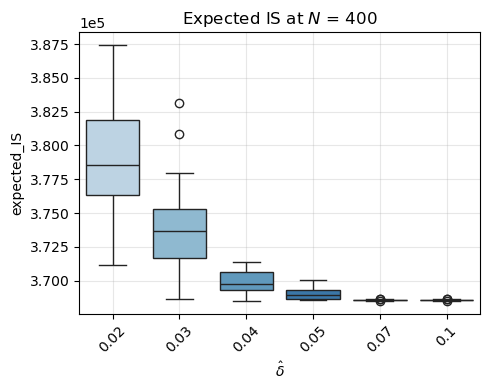

In [ ]:
nTrades = 400
fig, ax = plt.subplots(1, 1, figsize=(5, 4))

# Filter data for specific chanceThresh
df_filtered = df_expected_IS[df_expected_IS['nTrades'] == nTrades]

# Create boxplot with custom color palette
sns.boxplot(data=df_filtered, x='chanceThresh', y='expected_IS', ax=ax, palette=colors_thresh)

# Set titles and labels
ax.set_title(f'Expected IS at $N$ = {nTrades}')
ax.set_xlabel(r'$\hat{\delta}$')  # Fixed xlabel to match your other plots
ax.tick_params(axis='x', rotation=45)
ax.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../plots/expected_IS_boxplot_N400.pdf', bbox_inches='tight')
plt.show()